# 20 · Set 5g: the ideas from Routing_Experiment_Ideas.docx, tested on this task (CPU, about 10–15 minutes)

**Step 0, scoring audit.** Exact match marks "Gardnerville, Nevada" wrong when the gold answer is "Gardnerville". Every idea below is
therefore scored twice: with a corrected label ("substantially right": exact match, or token F1 of at least 0.5, or the gold answer
contained in the answer) and with exact match as before. Every answer with its three scores is saved for hand checking.

| Idea from the document | What is tested here | Variant named beforehand |
|---|---|---|
| 1 Five-voter gate | TF-IDF cosine, Jaccard, rare-token overlap, Dice and overlap coefficient between the question and the passages picked in the first try: majority vote with the original thresholds, three voters only, thresholds retuned, and a learned model on the continuous scores | Majority vote, original thresholds |
| 2 Rare routing margins | Rarity of the question's words (training-corpus frequency), the gap between the top passage scores, and their interaction | Rarity, margin and interaction |
| 3 Benefit-targeted probes | Predict "helps" directly, and expected gain = P(helps) − P(hurts) | Expected gain |
| 4 Mixture of experts (MoE) | Three experts (evidence, structure, confidence): equal weights, fixed tuned weights, question-dependent weights from a small gate, and a gate that selects one expert | Question-dependent weights |
| 5 Bundle of experts (BoE) | The same three experts, every output kept: votes, and a joint model with disagreement, rarity, margin and named interactions | Joint model with interactions |
| 6 Adaptive weighting and sharpening | A simple adaptive rule, and per-expert temperatures and weights | Per-expert temperatures |

Sequence-aware transitions (bridge retrieval) need new model runs and are not in this notebook.

Each idea is judged three ways, on all 400 questions cross-validated and in both transfer directions (old → fresh, fresh → old):
does its gate beat a random gate at the same budget; does it add to the fixed hidden-state probe; and how does it compare with the
cheap fixed setup (what AgentTTS picks). **No model is run and no GPU is needed.**

Output: `runs/Set_2__question-reading-routers/<timestamp>_cpu_ideas/results/` with `summary.md`, `set5g_ideas.xlsx`, `verdicts.jsonl`, `labels.jsonl`, and charts.

**Runtime → Change runtime type → CPU.**

In [1]:
# ==== settings ====
PROJECT_DIR = "/content/drive/MyDrive/0_EngD_assignments/0_Small_Big_Model_Switching"
EXPERIMENT  = "Set_2__question-reading-routers"
OLD_SWEEP_EXPERIMENT = "Set_1__3-modality-size"
FRESH_DATA  = f"{PROJECT_DIR}/data/hotpotqa_q/fresh200_c20_s43"
USE_EMBEDDING = True      # also use a small sentence-embedding model for the question and passages (downloads ~90 MB once)
CV_REPEATS = 2            # repeats of the 5-fold cross-validation over all 400 questions

EXPECTED_CODE = {
 "ssw.py": "c9fbdc7f6b91c58b607021b8be8c03ae2ff67dc1024fd2e24fffeb18e239ed98",
 "sweep.py": "9382292c6fe396cf79c73b212aaf6c2d677cae7f9311c3a5304f0578b52e6bb6",
 "routers.py": "8a293df1c8955716950f535cf9a3ced24439e00250173da1a3df110c0ed87304",
 "hidden.py": "574e6c1390e47c6de833a0c10b32c24eed0dee73a35eabc17f58842835e7f105",
 "final.py": "f18a6fba3d1bdd1f6700f6dc535f10ec0c41dbf5192b7b39ad097f8a1b88be53",
 "retriever_check.py": "fde08c549ecbd6bfc5527a42c731aa51dcff687a64818d68cf9cb30090e017e3",
 "ensemble.py": "5c5e87175d2484d806fda913a9555f71378a6031f050c37e89c20305942b76fc",
 "experts.py": "17ed39957e54853d178b47fa73ba328b50f0589b129ccb191a2efb0a2dea466b"
}

In [2]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [3]:
import glob, hashlib, json, os, shutil, subprocess, sys, time
from datetime import datetime
from zoneinfo import ZoneInfo
T_START = time.time()
def sha(p):
    return hashlib.sha256(open(p, "rb").read()).hexdigest()
CODE_DIR = "/content/set5code"
os.makedirs(CODE_DIR, exist_ok=True)
stale = []
for f, want in EXPECTED_CODE.items():
    shutil.copy(f"{PROJECT_DIR}/code/{f}", f"{CODE_DIR}/{f}")
    if sha(f"{CODE_DIR}/{f}") != want:
        stale.append(f)
assert not stale, (f"Drive is serving a different version of {stale} than this notebook was made for. Wait two minutes, then "
                   "Runtime -> Disconnect and delete runtime, and run again.")
sweeps = [d for d in sorted(glob.glob(f"{PROJECT_DIR}/runs/{OLD_SWEEP_EXPERIMENT}/*")) if "_dryrun" not in d and os.path.exists(f"{d}/results/per_question.jsonl")
          and os.path.exists(f"{d}/sweep_status.json") and json.load(open(f"{d}/sweep_status.json")).get("complete")]
hidden = [d for d in sorted(glob.glob(f"{PROJECT_DIR}/runs/{EXPERIMENT}/*_hidden")) if os.path.exists(f"{d}/step/hidden_retrieve_q7.jsonl")
          and os.path.exists(f"{d}/step/hidden_answer_l8.jsonl")]
fresh = [d for d in sorted(glob.glob(f"{PROJECT_DIR}/runs/{EXPERIMENT}/*_final")) if os.path.exists(f"{d}/step/hidden_retrieve_q7.jsonl")
         and os.path.exists(f"{d}/step/hidden_answer_l8.jsonl")]
assert sweeps and hidden and fresh, "Needs the finished runs of notebooks 11, 16, 17 and 18."
OLD_SWEEP, OLD_HIDDEN, FRESH_RUN = sweeps[-1], hidden[-1], fresh[-1]
OLD_DATA = json.load(open(f"{OLD_SWEEP}/config.json"))["data_dir"]
SESSION = datetime.now(ZoneInfo("Asia/Singapore")).strftime("%Y%m%d-%H%M%S")
RUN_DIR = f"{PROJECT_DIR}/runs/{EXPERIMENT}/{SESSION}_cpu_ideas"
for d in (f"{RUN_DIR}/code", f"{RUN_DIR}/logs"):
    os.makedirs(d, exist_ok=True)
for f in EXPECTED_CODE:
    shutil.copy(f"{CODE_DIR}/{f}", f"{RUN_DIR}/code/{f}")
json.dump({"experiment": EXPERIMENT, "set": "5g ideas document", "old_sweep": OLD_SWEEP, "old_hidden": OLD_HIDDEN, "fresh_run": FRESH_RUN,
           "old_data": OLD_DATA, "fresh_data": FRESH_DATA, "use_embedding": USE_EMBEDDING, "cv_repeats": CV_REPEATS, "code": EXPECTED_CODE, "started": SESSION},
          open(f"{RUN_DIR}/config.json", "w"), indent=1)
print("Code files: current.")
print("Old questions:  ", OLD_SWEEP, "\n                ", OLD_HIDDEN)
print("Fresh questions:", FRESH_RUN)
print("Run folder:     ", RUN_DIR)

Code files: current.
Old questions:   /content/drive/MyDrive/0_EngD_assignments/0_Small_Big_Model_Switching/runs/Set_1__3-modality-size/20261004-165402_A100 
                 /content/drive/MyDrive/0_EngD_assignments/0_Small_Big_Model_Switching/runs/Set_2__question-reading-routers/20261007-075955_A100_hidden
Fresh questions: /content/drive/MyDrive/0_EngD_assignments/0_Small_Big_Model_Switching/runs/Set_2__question-reading-routers/20261007-162319_A100_final
Run folder:      /content/drive/MyDrive/0_EngD_assignments/0_Small_Big_Model_Switching/runs/Set_2__question-reading-routers/20261008-090219_cpu_ideas


In [4]:
# optional packages: without them the notebook still runs (no embedding families, no SMOTE row)
import importlib.util
if USE_EMBEDDING and importlib.util.find_spec("sentence_transformers") is None:
    print("installing sentence-transformers ...")
    !pip install -q sentence-transformers
if importlib.util.find_spec("imblearn") is None:
    print("installing imbalanced-learn ...")
    !pip install -q imbalanced-learn

### Run every idea (about 10–15 minutes)

[01:02:21] experts code version 5g.1

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 4270.59it/s]
[01:13:58] 400 questions; question embedding: all-MiniLM-L6-v2
[01:14:10]   answerer | old -> fresh | fold 1/1 done
[01:14:46]   answerer | fresh -> old | fold 1/1 done
[01:15:26]   answerer | all 400, cross-validated | fold 1/10 done
[01:15:36]   answerer | all 400, cross-validated | fold 2/10 done
[01:15:45]   answerer | all 400, cross-validated | fold 3/10 done
[01:15:57]   answerer | all 400, cross-validated | fold 4/10 done
[01:16:07]   answerer | all 400, cross-validated | fold 5/10 done
[01:16:16]   answerer | all 400, cross-validated | fold 6/10 done
[01:16:28]   answerer | all 400, cross-validated | fold 7/10 done
[01:16:39]   answerer | all 400, cross-validated | fold 8/10 done
[01:16:48]   answerer | all 400, cross-validated | fold 9/10 done
[01:16:59]   answerer | all 400, cross-validated | fold 10/10 done
[01:20:08] corrected label (substantially right) | answerer don

# Set 5g - the ideas from Routing_Experiment_Ideas.docx, tested on this task

Code version 5g.1. 400 questions (200 old, 200 fresh). No model was run. Question embedding: all-MiniLM-L6-v2.
Both question sets have already been used for development, so nothing here is an untouched test. Three evaluations are reported so that no single sample decides.

## 0. Scoring audit

Exact match marks an answer wrong when it differs from the gold string in any way ('Gardnerville, Nevada' against 'Gardnerville'). The corrected label counts an answer as substantially right when it matches exactly, or its token F1 with the gold answer is at least 0.5, or it contains the gold answer; yes/no answers must match exactly. A hand check of about 90 borderline answers on the fresh questions found roughly 1 in 20 accepted wrongly and a similar share rejected wrongly, so it is much closer to correctness than exact match, but not perfect. Every answer is listed in `results/labels.jsonl` for checking.

| Measure | Old 200 | Fresh 200 |
|---|---|---|
| Qwen 32B: exact match | 63.5% | 53.5% |
| Qwen 32B: F1 | 77.8% | 69.7% |
| Qwen 32B: substantially right | 83.0% | 73.5% |
| Llama 8B: exact match | 54.0% | 48.5% |
| Llama 8B: F1 | 68.8% | 65.1% |
| Llama 8B: substantially right | 74.0% | 72.5% |
| Gap, exact match (points) | +9.5 | +5.0 |
| Gap, substantially right (points) | +9.0 | +1.0 |
| 'Escalating helps', exact match | 25 | 26 |
| 'Escalating helps', corrected | 25 | 16 |
| 'Escalating hurts', exact match | 6 | 16 |
| 'Escalating hurts', corrected | 7 | 14 |
| Share of exact-match 'helps' that is only wording | 40.0% | 53.8% |
| Found both: Qwen 32B right (corrected) | 86.2% | 82.1% |
| Missed a passage: Qwen 32B right (corrected) | 66.7% | 46.9% |
| Missed a passage, 3 tries: Qwen 32B right (corrected) | 69.7% | 61.2% |

Because the routing target ('the Llama 8B answer is no worse than the Qwen 32B answer') is built from these labels, a large part of what the earlier probes were trained to find was a difference in wording. All results below are given first with the corrected label and then with exact match.

## 1. Answerer decision (keep the Llama 8B answer, or ask the Qwen 32B?) - corrected label (substantially right)

All 400 questions, cross-validated. The fixed probe scores 0.78; its gate is +4.1 points against a random gate and +1.0 points of accuracy against the cheap fixed setup.

### One row per idea (the variant named beforehand)

| Idea | Variant named beforehand | Separation | Idea minus fixed probe | 95% low | 95% high | Gate vs random (points) | 95% low | 95% high | Works alone (beats a random gate in all three evaluations) | Fixed probe + idea, minus fixed probe | 95% low | 95% high | Adds to the fixed probe (interval excludes zero, ahead in both transfers) | Gate accuracy vs cheap fixed setup (points) | 95% low | 95% high | Compute vs cheap fixed setup |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| 1 Five-voter gate | Five voters: majority vote, original thresholds | 0.47 | -0.31 | -0.42 | -0.19 | -0.4 | -2.3 | +1.4 | no | -0.08 | -0.14 | -0.01 | no | -2.7 | -5.5 | -0.2 | -18% |
| 2 Rare routing margins | Rare margins: rarity, margin and their interaction | 0.57 | -0.22 | -0.32 | -0.11 | +1.0 | -0.2 | +2.2 | no | -0.05 | -0.12 | +0.01 | no | -3.4 | -6.9 | +0.1 | -42% |
| 3 Benefit-targeted probes | Benefit probe: expected gain (helps minus hurts) | 0.76 | -0.03 | -0.08 | +0.02 | +3.8 | +2.0 | +5.6 | yes | -0.01 | -0.06 | +0.02 | no | +0.8 | -1.6 | +3.1 | -26% |
| 4 Mixture of experts (MoE) | MoE: question-dependent weights (learned gate) | 0.69 | -0.09 | -0.16 | -0.01 | +2.4 | +0.8 | +4.0 | yes | -0.03 | -0.08 | +0.02 | no | -1.0 | -3.8 | +1.7 | -30% |
| 5 Bundle of experts (BoE) | BoE: joint model on every output with named interactions | 0.70 | -0.08 | -0.15 | -0.00 | +2.7 | +1.1 | +4.4 | yes | -0.03 | -0.06 | +0.01 | no | -0.2 | -2.6 | +2.3 | -25% |
| 6 Adaptive weighting and sharpening | Sharpening: per-expert temperatures and weights | 0.65 | -0.13 | -0.22 | -0.04 | +2.7 | +1.1 | +4.4 | yes | -0.04 | -0.09 | +0.00 | no | -0.9 | -3.6 | +1.9 | -32% |

### Every variant

**all 400, cross-validated**

| Model | Separation | Minus the fixed probe | Minus the fixed probe: low | Minus the fixed probe: high | Share acted on | Gate minus random: accuracy (points) | Gate minus random: accuracy, low | Gate minus random: accuracy, high | Gate accuracy minus the cheap fixed setup (points) | vs cheap fixed setup, low | vs cheap fixed setup, high | Gate compute vs the cheap fixed setup |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| Reference: one fixed hidden-state probe, as in notebooks 17 and 18 | 0.78 | +0.00 | +0.00 | +0.00 | 37.1% | +4.1 | +2.3 | +5.9 | +1.0 | -1.4 | +3.4 | -27% |
| Benefit probe: predicts 'helps' only | 0.78 | +0.00 | +0.00 | +0.00 | 37.1% | +4.1 | +2.3 | +5.9 | +1.0 | -1.4 | +3.4 | -27% |
| Fixed probe + Benefit probe: expected gain (helps minus hurts) | 0.77 | -0.01 | -0.06 | +0.02 | 38.9% | +3.6 | +1.6 | +5.3 | +0.5 | -1.9 | +2.7 | -26% |
| Fixed probe + BoE: joint model on every output with named interactions | 0.76 | -0.03 | -0.06 | +0.01 | 39.6% | +3.0 | +1.3 | +4.6 | +0.0 | -2.4 | +2.2 | -26% |
| Benefit probe: expected gain (helps minus hurts) | 0.76 | -0.03 | -0.08 | +0.02 | 38.9% | +3.8 | +2.0 | +5.6 | +0.8 | -1.6 | +3.1 | -26% |
| Fixed probe + MoE: question-dependent weights (learned gate) | 0.75 | -0.03 | -0.08 | +0.02 | 33.6% | +3.4 | +1.7 | +5.1 | +0.1 | -2.4 | +2.6 | -29% |
| Fixed probe + Sharpening: per-expert temperatures and weights | 0.74 | -0.04 | -0.09 | +0.00 | 31.0% | +3.2 | +1.3 | +4.9 | -0.2 | -3.0 | +2.3 | -31% |
| Fixed probe + Rare margins: rarity, margin and their interaction | 0.73 | -0.05 | -0.12 | +0.01 | 17.8% | +3.6 | +2.0 | +5.3 | -0.5 | -3.5 | +2.5 | -39% |
| Expert: confidence (retriever facts and hidden state, answer probe, token probabilities) | 0.71 | -0.07 | -0.14 | -0.00 | 39.1% | +2.7 | +0.9 | +4.4 | -0.4 | -2.9 | +2.1 | -26% |
| Adaptive rule: when the experts disagree, follow the most worried one | 0.71 | -0.07 | -0.15 | +0.01 | 33.6% | +2.8 | +0.9 | +4.7 | -0.5 | -2.8 | +2.0 | -29% |
| Fixed probe + Five voters: majority vote, original thresholds | 0.71 | -0.08 | -0.14 | -0.01 | 40.9% | +3.1 | +1.0 | +4.8 | +0.1 | -2.4 | +2.5 | -26% |
| BoE: joint model on every output with named interactions | 0.70 | -0.08 | -0.15 | -0.00 | 40.6% | +2.7 | +1.1 | +4.4 | -0.2 | -2.6 | +2.3 | -25% |
| MoE: equal weights | 0.69 | -0.09 | -0.17 | -0.00 | 29.4% | +3.0 | +1.3 | +4.9 | -0.5 | -3.0 | +2.3 | -32% |
| MoE: question-dependent weights (learned gate) | 0.69 | -0.09 | -0.16 | -0.01 | 32.1% | +2.4 | +0.8 | +4.0 | -1.0 | -3.8 | +1.7 | -30% |
| MoE: fixed weights tuned on training questions | 0.68 | -0.11 | -0.18 | -0.02 | 35.5% | +2.3 | +0.7 | +4.1 | -0.9 | -3.4 | +1.7 | -28% |
| Benefit probe: predicts 'helps' only on every expert output | 0.68 | -0.11 | -0.18 | -0.02 | 35.8% | +2.3 | +0.7 | +4.1 | -0.9 | -3.4 | +1.7 | -28% |
| MoE: the gate selects one expert per question | 0.68 | -0.11 | -0.18 | -0.04 | 38.1% | +2.1 | +0.3 | +3.7 | -1.0 | -3.5 | +1.5 | -27% |
| BoE: every expert votes, ties broken by the mean score | 0.67 | -0.12 | -0.19 | -0.03 | 30.0% | +2.2 | +0.6 | +4.0 | -1.2 | -3.6 | +1.4 | -32% |
| BoE: joint boosted trees on every output | 0.66 | -0.13 | -0.19 | -0.06 | 38.1% | +1.8 | +0.2 | +3.5 | -1.2 | -3.6 | +1.2 | -27% |
| Sharpening: per-expert temperatures and weights | 0.65 | -0.13 | -0.22 | -0.04 | 28.9% | +2.7 | +1.1 | +4.4 | -0.9 | -3.6 | +1.9 | -32% |
| Fixed probe + Five voters: learned model on the continuous scores, coverage and redundancy | 0.65 | -0.13 | -0.20 | -0.06 | 37.2% | +2.0 | +0.4 | +3.6 | -1.1 | -3.6 | +1.4 | -28% |
| Benefit probe: expected gain (helps minus hurts) on every expert output | 0.65 | -0.14 | -0.23 | -0.04 | 36.0% | +2.4 | +0.6 | +4.1 | -0.7 | -3.4 | +1.9 | -28% |
| Rare margins: rarity, margin and their interaction | 0.57 | -0.22 | -0.32 | -0.11 | 13.2% | +1.0 | -0.2 | +2.2 | -3.4 | -6.9 | +0.1 | -42% |
| Rare margins: rarity only | 0.55 | -0.24 | -0.33 | -0.13 | 23.5% | +1.0 | -0.4 | +2.4 | -2.9 | -6.1 | +0.4 | -36% |
| Expert: evidence (lexical support, five voters, rare entities) | 0.54 | -0.25 | -0.34 | -0.15 | 20.1% | +0.5 | -0.7 | +2.0 | -3.5 | -6.6 | -0.2 | -38% |
| Expert: structure (bridges, coverage gaps, redundancy, left-out passages) | 0.53 | -0.25 | -0.37 | -0.12 | 34.8% | -1.0 | -2.8 | +0.7 | -4.2 | -7.0 | -1.5 | -29% |
| Five voters: majority vote, thresholds retuned on training questions | 0.49 | -0.30 | -0.39 | -0.18 | 40.9% | -1.4 | -3.2 | +0.2 | -4.4 | -7.1 | -1.9 | -25% |
| Rare margins: margin only | 0.48 | -0.31 | -0.42 | -0.19 | 26.0% | -0.4 | -1.9 | +0.9 | -4.1 | -7.3 | -1.0 | -35% |
| Five voters: majority vote, original thresholds | 0.47 | -0.31 | -0.42 | -0.19 | 53.0% | -0.4 | -2.3 | +1.4 | -2.7 | -5.5 | -0.2 | -18% |
| Five voters: three voters only (TF-IDF, rare overlap, overlap coefficient) | 0.47 | -0.32 | -0.43 | -0.19 | 86.0% | +0.2 | -0.8 | +1.1 | -0.5 | -1.6 | +0.6 | +2% |
| Five voters: learned model on the continuous scores, coverage and redundancy | 0.43 | -0.35 | -0.45 | -0.24 | 35.6% | -1.2 | -2.6 | +0.3 | -4.4 | -7.4 | -1.5 | -29% |

**old -> fresh**

| Model | Separation | Minus the fixed probe | Minus the fixed probe: low | Minus the fixed probe: high | Share acted on | Gate minus random: accuracy (points) | Gate minus random: accuracy, low | Gate minus random: accuracy, high | Gate accuracy minus the cheap fixed setup (points) | vs cheap fixed setup, low | vs cheap fixed setup, high | Gate compute vs the cheap fixed setup |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| Reference: one fixed hidden-state probe, as in notebooks 17 and 18 | 0.77 | +0.00 | +0.00 | +0.00 | 32.5% | +3.7 | +1.3 | +6.4 | +3.0 | -1.0 | +7.0 | -30% |
| Adaptive rule: when the experts disagree, follow the most worried one | 0.83 | +0.06 | -0.02 | +0.14 | 29.0% | +2.7 | -0.1 | +5.8 | +2.0 | -1.0 | +5.5 | -32% |
| MoE: equal weights | 0.80 | +0.03 | -0.09 | +0.14 | 29.0% | +4.2 | +1.4 | +7.1 | +3.5 | +0.5 | +7.0 | -33% |
| Fixed probe + MoE: question-dependent weights (learned gate) | 0.80 | +0.03 | -0.06 | +0.12 | 31.5% | +4.2 | +1.7 | +7.0 | +3.5 | +0.0 | +7.0 | -31% |
| Fixed probe + BoE: joint model on every output with named interactions | 0.79 | +0.02 | -0.06 | +0.11 | 57.0% | +2.4 | +0.1 | +5.1 | +2.0 | -0.5 | +5.0 | -14% |
| BoE: every expert votes, ties broken by the mean score | 0.79 | +0.02 | -0.09 | +0.15 | 26.5% | +3.7 | +0.9 | +7.0 | +3.0 | -0.5 | +6.5 | -34% |
| Expert: confidence (retriever facts and hidden state, answer probe, token probabilities) | 0.79 | +0.02 | -0.12 | +0.14 | 35.5% | +3.6 | +1.0 | +6.8 | +3.0 | -0.5 | +6.0 | -28% |
| MoE: question-dependent weights (learned gate) | 0.79 | +0.02 | -0.12 | +0.14 | 33.0% | +4.2 | +1.5 | +7.3 | +3.5 | +0.0 | +7.0 | -30% |
| MoE: the gate selects one expert per question | 0.79 | +0.02 | -0.12 | +0.14 | 35.5% | +3.6 | +1.0 | +6.8 | +3.0 | -0.5 | +6.0 | -28% |
| Fixed probe + Sharpening: per-expert temperatures and weights | 0.78 | +0.02 | -0.08 | +0.14 | 56.5% | +0.9 | -1.6 | +3.6 | +0.5 | -2.0 | +3.0 | -15% |
| Fixed probe + Five voters: majority vote, original thresholds | 0.77 | +0.00 | -0.11 | +0.14 | 35.0% | +3.2 | +0.6 | +6.1 | +2.5 | -0.5 | +6.0 | -29% |
| Benefit probe: predicts 'helps' only | 0.77 | +0.00 | +0.00 | +0.00 | 32.5% | +3.7 | +1.3 | +6.4 | +3.0 | -1.0 | +7.0 | -30% |
| Benefit probe: expected gain (helps minus hurts) | 0.77 | +0.00 | +0.00 | +0.00 | 32.5% | +3.7 | +1.3 | +6.4 | +3.0 | -1.0 | +7.0 | -30% |
| Fixed probe + Benefit probe: expected gain (helps minus hurts) | 0.77 | +0.00 | +0.00 | +0.00 | 32.5% | +3.7 | +1.3 | +6.4 | +3.0 | -1.0 | +7.0 | -30% |
| Fixed probe + Five voters: learned model on the continuous scores, coverage and redundancy | 0.77 | -0.00 | -0.06 | +0.05 | 38.0% | +2.6 | +0.0 | +5.4 | +2.0 | -1.5 | +5.5 | -27% |
| Fixed probe + Rare margins: rarity, margin and their interaction | 0.76 | -0.01 | -0.07 | +0.05 | 15.5% | +3.8 | +1.4 | +6.3 | +3.0 | -1.0 | +7.5 | -41% |
| Benefit probe: predicts 'helps' only on every expert output | 0.75 | -0.02 | -0.13 | +0.10 | 64.5% | +0.9 | -1.5 | +3.2 | +0.5 | -1.5 | +3.0 | -10% |
| Benefit probe: expected gain (helps minus hurts) on every expert output | 0.75 | -0.02 | -0.13 | +0.10 | 64.5% | +0.9 | -1.5 | +3.2 | +0.5 | -1.5 | +3.0 | -10% |
| BoE: joint model on every output with named interactions | 0.75 | -0.02 | -0.15 | +0.11 | 67.5% | +1.8 | -0.1 | +3.9 | +1.5 | +0.0 | +3.5 | -8% |
| MoE: fixed weights tuned on training questions | 0.75 | -0.02 | -0.15 | +0.10 | 61.0% | +0.4 | -2.1 | +2.8 | +0.0 | -2.5 | +2.5 | -12% |
| Sharpening: per-expert temperatures and weights | 0.74 | -0.03 | -0.17 | +0.11 | 63.0% | +0.4 | -1.8 | +2.5 | +0.0 | -2.0 | +2.0 | -11% |
| BoE: joint boosted trees on every output | 0.64 | -0.13 | -0.32 | +0.06 | 53.5% | +1.5 | -1.1 | +4.1 | +1.0 | -2.5 | +4.5 | -17% |
| Rare margins: rarity, margin and their interaction | 0.63 | -0.14 | -0.30 | +0.01 | 9.0% | +1.9 | +0.4 | +3.9 | +1.0 | -4.0 | +6.0 | -45% |
| Rare margins: margin only | 0.61 | -0.16 | -0.37 | +0.07 | 27.5% | +0.2 | -2.5 | +2.9 | -0.5 | -5.0 | +3.5 | -34% |
| Expert: evidence (lexical support, five voters, rare entities) | 0.57 | -0.20 | -0.37 | -0.03 | 12.5% | +1.9 | +0.2 | +3.8 | +1.0 | -4.0 | +5.5 | -43% |
| Expert: structure (bridges, coverage gaps, redundancy, left-out passages) | 0.56 | -0.21 | -0.45 | +0.01 | 36.5% | -0.4 | -3.2 | +2.6 | -1.0 | -5.0 | +3.0 | -28% |
| Five voters: learned model on the continuous scores, coverage and redundancy | 0.56 | -0.21 | -0.37 | -0.06 | 39.5% | -0.9 | -3.6 | +1.8 | -1.5 | -5.0 | +2.5 | -27% |
| Rare margins: rarity only | 0.55 | -0.22 | -0.36 | -0.10 | 19.5% | +2.3 | +0.6 | +4.4 | +1.5 | -3.5 | +6.5 | -39% |
| Five voters: three voters only (TF-IDF, rare overlap, overlap coefficient) | 0.52 | -0.25 | -0.47 | -0.02 | 100.0% | +0.0 | +0.0 | +0.0 | +0.0 | +0.0 | +0.0 | +11% |
| Five voters: majority vote, thresholds retuned on training questions | 0.46 | -0.31 | -0.56 | -0.05 | 41.0% | -0.9 | -3.5 | +1.9 | -1.5 | -5.5 | +2.0 | -26% |
| Five voters: majority vote, original thresholds | 0.46 | -0.31 | -0.54 | -0.07 | 53.5% | -1.0 | -3.9 | +1.6 | -1.5 | -5.5 | +2.5 | -18% |

**fresh -> old**

| Model | Separation | Minus the fixed probe | Minus the fixed probe: low | Minus the fixed probe: high | Share acted on | Gate minus random: accuracy (points) | Gate minus random: accuracy, low | Gate minus random: accuracy, high | Gate accuracy minus the cheap fixed setup (points) | vs cheap fixed setup, low | vs cheap fixed setup, high | Gate compute vs the cheap fixed setup |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| Reference: one fixed hidden-state probe, as in notebooks 17 and 18 | 0.75 | +0.00 | +0.00 | +0.00 | 34.0% | +4.4 | +1.8 | +7.1 | -1.5 | -5.0 | +2.5 | -29% |
| Fixed probe + MoE: question-dependent weights (learned gate) | 0.79 | +0.04 | -0.06 | +0.14 | 34.5% | +5.9 | +3.0 | +8.5 | +0.0 | -3.5 | +4.0 | -29% |
| Fixed probe + Rare margins: rarity, margin and their interaction | 0.76 | +0.01 | -0.11 | +0.14 | 12.0% | +3.4 | +1.1 | +5.9 | -4.5 | -9.0 | +0.0 | -43% |
| MoE: question-dependent weights (learned gate) | 0.76 | +0.01 | -0.12 | +0.12 | 38.0% | +5.6 | +2.9 | +8.2 | +0.0 | -3.5 | +4.0 | -27% |
| Benefit probe: predicts 'helps' only | 0.75 | +0.00 | +0.00 | +0.00 | 34.0% | +4.4 | +1.8 | +7.1 | -1.5 | -5.0 | +2.5 | -29% |
| BoE: every expert votes, ties broken by the mean score | 0.74 | -0.01 | -0.15 | +0.13 | 27.5% | +3.0 | +0.4 | +5.7 | -3.5 | -7.5 | +1.0 | -33% |
| MoE: equal weights | 0.74 | -0.02 | -0.16 | +0.13 | 22.0% | +3.5 | +0.9 | +6.3 | -3.5 | -7.5 | +0.5 | -36% |
| Fixed probe + Benefit probe: expected gain (helps minus hurts) | 0.73 | -0.02 | -0.09 | +0.04 | 31.0% | +4.2 | +1.6 | +7.2 | -2.0 | -6.0 | +2.0 | -31% |
| MoE: the gate selects one expert per question | 0.72 | -0.03 | -0.14 | +0.07 | 42.5% | +4.7 | +1.9 | +7.4 | -0.5 | -4.5 | +3.0 | -24% |
| Expert: confidence (retriever facts and hidden state, answer probe, token probabilities) | 0.72 | -0.03 | -0.14 | +0.07 | 39.5% | +4.9 | +2.4 | +7.5 | -0.5 | -4.5 | +3.5 | -26% |
| Adaptive rule: when the experts disagree, follow the most worried one | 0.71 | -0.04 | -0.18 | +0.11 | 28.5% | +2.9 | +0.4 | +5.6 | -3.5 | -7.5 | +1.0 | -32% |
| Fixed probe + Sharpening: per-expert temperatures and weights | 0.71 | -0.04 | -0.12 | +0.04 | 37.5% | +4.1 | +1.5 | +6.7 | -1.5 | -5.0 | +2.5 | -27% |
| Benefit probe: expected gain (helps minus hurts) | 0.69 | -0.06 | -0.17 | +0.04 | 35.0% | +3.4 | +0.7 | +6.2 | -2.5 | -6.5 | +1.5 | -28% |
| Fixed probe + Five voters: learned model on the continuous scores, coverage and redundancy | 0.68 | -0.07 | -0.18 | +0.05 | 26.0% | +1.7 | -1.3 | +4.6 | -5.0 | -9.0 | -1.0 | -35% |
| Benefit probe: predicts 'helps' only on every expert output | 0.68 | -0.07 | -0.19 | +0.04 | 38.0% | +4.6 | +2.1 | +7.3 | -1.0 | -5.0 | +3.0 | -27% |
| MoE: fixed weights tuned on training questions | 0.68 | -0.07 | -0.19 | +0.03 | 36.0% | +4.8 | +2.2 | +7.4 | -1.0 | -5.0 | +3.0 | -28% |
| Fixed probe + BoE: joint model on every output with named interactions | 0.67 | -0.08 | -0.18 | +0.02 | 50.5% | +3.5 | +0.8 | +6.2 | -1.0 | -4.5 | +3.0 | -19% |
| Fixed probe + Five voters: majority vote, original thresholds | 0.66 | -0.09 | -0.18 | +0.02 | 38.5% | +3.0 | +0.1 | +6.0 | -2.5 | -6.0 | +1.0 | -27% |
| Sharpening: per-expert temperatures and weights | 0.64 | -0.11 | -0.22 | +0.00 | 41.5% | +3.8 | +1.3 | +6.4 | -1.5 | -5.5 | +2.5 | -25% |
| Expert: evidence (lexical support, five voters, rare entities) | 0.62 | -0.14 | -0.32 | +0.06 | 21.0% | +2.1 | -0.2 | +4.6 | -5.0 | -9.5 | -0.5 | -38% |
| Rare margins: rarity, margin and their interaction | 0.60 | -0.16 | -0.34 | +0.04 | 9.0% | +1.2 | -0.3 | +3.0 | -7.0 | -12.0 | -2.0 | -45% |
| Rare margins: margin only | 0.59 | -0.16 | -0.30 | -0.02 | 25.5% | -0.8 | -2.9 | +1.6 | -7.5 | -12.0 | -3.0 | -35% |
| BoE: joint boosted trees on every output | 0.59 | -0.16 | -0.28 | -0.03 | 49.5% | +2.5 | -0.0 | +5.3 | -2.0 | -5.5 | +2.0 | -20% |
| BoE: joint model on every output with named interactions | 0.58 | -0.17 | -0.31 | -0.03 | 56.0% | +2.0 | -0.7 | +4.8 | -2.0 | -6.0 | +2.0 | -16% |
| Benefit probe: expected gain (helps minus hurts) on every expert output | 0.58 | -0.17 | -0.30 | -0.04 | 47.5% | +1.7 | -0.6 | +4.6 | -3.0 | -7.0 | +1.0 | -21% |
| Five voters: majority vote, thresholds retuned on training questions | 0.57 | -0.18 | -0.31 | -0.05 | 64.5% | +3.2 | +0.7 | +5.8 | +0.0 | -3.0 | +3.5 | -11% |
| Rare margins: rarity only | 0.57 | -0.18 | -0.38 | +0.01 | 16.5% | +0.5 | -1.5 | +2.6 | -7.0 | -11.5 | -2.0 | -40% |
| Expert: structure (bridges, coverage gaps, redundancy, left-out passages) | 0.57 | -0.19 | -0.40 | +0.01 | 30.5% | +1.3 | -1.4 | +4.0 | -5.0 | -9.0 | -0.5 | -32% |
| Five voters: learned model on the continuous scores, coverage and redundancy | 0.52 | -0.23 | -0.39 | -0.05 | 29.0% | -0.1 | -2.7 | +2.6 | -6.5 | -11.0 | -2.0 | -33% |
| Five voters: majority vote, original thresholds | 0.48 | -0.27 | -0.43 | -0.11 | 59.5% | -0.4 | -2.9 | +2.2 | -4.0 | -7.5 | -0.5 | -14% |
| Five voters: three voters only (TF-IDF, rare overlap, overlap coefficient) | 0.44 | -0.31 | -0.46 | -0.15 | 45.0% | -1.5 | -4.0 | +1.1 | -6.5 | -10.5 | -2.0 | -24% |

Details (old -> fresh):

- Five voters: majority vote, thresholds retuned on training questions: thresholds TF-IDF cosine: 0.350, Jaccard: 0.041, rare-token overlap: 0.667, Dice: 0.078, overlap coefficient: 0.625
- MoE: question-dependent weights (learned gate): mean weight on test questions - evidence 0.00, structure 0.00, confidence 1.00; weight spread across questions 0.00
- MoE: the gate selects one expert per question: share of test questions sent to each expert - evidence 0.00, structure 0.00, confidence 1.00
- Benefit probe: predicts 'helps' only: 'helps' on 25 training questions
- Benefit probe: expected gain (helps minus hurts): 'hurts' has only 7 training questions: a constant was used
- Benefit probe: predicts 'helps' only on every expert output: 'helps' on 25 training questions
- Benefit probe: expected gain (helps minus hurts) on every expert output: 'hurts' has only 7 training questions: a constant was used

## 2. Retriever decision (stop after one retrieval try, or try twice more?) - corrected label (substantially right)

All 400 questions, cross-validated. The fixed probe scores 0.66; its gate is +1.3 points against a random gate and +0.5 points of accuracy against the cheap fixed setup. For the retriever decision 'gate vs random' counts how often both passages are found.

### One row per idea (the variant named beforehand)

| Idea | Variant named beforehand | Separation | Idea minus fixed probe | 95% low | 95% high | Gate vs random (points) | 95% low | 95% high | Works alone (beats a random gate in all three evaluations) | Fixed probe + idea, minus fixed probe | 95% low | 95% high | Adds to the fixed probe (interval excludes zero, ahead in both transfers) | Gate accuracy vs cheap fixed setup (points) | 95% low | 95% high | Compute vs cheap fixed setup |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| 1 Five-voter gate | Five voters: majority vote, original thresholds | 0.49 | -0.17 | -0.26 | -0.08 | +1.6 | +0.2 | +3.1 | yes | -0.04 | -0.09 | +0.00 | no | +0.3 | -1.0 | +1.5 | +3% |
| 2 Rare routing margins | Rare margins: rarity, margin and their interaction | 0.58 | -0.07 | -0.15 | +0.01 | +0.3 | -0.4 | +1.2 | no | +0.00 | -0.04 | +0.04 | no | +0.1 | +0.0 | +0.4 | +1% |
| 3 Benefit-targeted probes | Benefit probe: expected gain (helps minus hurts) | 0.54 | -0.12 | -0.20 | -0.03 | +0.5 | -0.6 | +1.8 | no | -0.03 | -0.08 | +0.01 | no | +0.1 | -0.7 | +1.1 | +3% |
| 4 Mixture of experts (MoE) | MoE: question-dependent weights (learned gate) | 0.70 | +0.04 | -0.02 | +0.10 | +2.7 | +1.3 | +4.3 | yes | +0.06 | +0.02 | +0.09 | yes | +0.0 | -1.0 | +1.0 | +3% |
| 5 Bundle of experts (BoE) | BoE: joint model on every output with named interactions | 0.69 | +0.03 | -0.02 | +0.10 | +2.9 | +1.4 | +4.6 | yes | +0.04 | +0.01 | +0.08 | yes | +0.1 | -1.1 | +1.4 | +2% |
| 6 Adaptive weighting and sharpening | Sharpening: per-expert temperatures and weights | 0.70 | +0.05 | -0.01 | +0.11 | +2.9 | +1.4 | +4.5 | yes | +0.05 | +0.02 | +0.09 | yes | +0.1 | -1.0 | +1.3 | +3% |

### Every variant

**all 400, cross-validated**

| Model | Separation | Minus the fixed probe | Minus the fixed probe: low | Minus the fixed probe: high | Share acted on | Gate minus random: both passages found (points) | Gate minus random: both passages found, low | Gate minus random: both passages found, high | Gate accuracy minus the cheap fixed setup (points) | vs cheap fixed setup, low | vs cheap fixed setup, high | Gate compute vs the cheap fixed setup |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| Reference: one fixed hidden-state probe, as in notebooks 17 and 18 | 0.66 | +0.00 | +0.00 | +0.00 | 17.5% | +1.3 | +0.1 | +2.7 | +0.5 | -0.6 | +1.5 | +3% |
| MoE: equal weights | 0.73 | +0.07 | +0.00 | +0.14 | 16.5% | +3.1 | +1.5 | +4.7 | +0.3 | -0.7 | +1.4 | +3% |
| BoE: every expert votes, ties broken by the mean score | 0.72 | +0.07 | +0.00 | +0.13 | 16.5% | +3.1 | +1.5 | +4.7 | +0.4 | -0.6 | +1.5 | +3% |
| MoE: fixed weights tuned on training questions | 0.72 | +0.06 | -0.00 | +0.12 | 14.9% | +2.9 | +1.4 | +4.5 | +0.3 | -0.9 | +1.5 | +3% |
| Fixed probe + MoE: question-dependent weights (learned gate) | 0.71 | +0.06 | +0.02 | +0.09 | 16.0% | +2.7 | +1.2 | +4.3 | +0.3 | -0.7 | +1.1 | +3% |
| Fixed probe + Sharpening: per-expert temperatures and weights | 0.71 | +0.05 | +0.02 | +0.09 | 14.5% | +2.9 | +1.4 | +4.6 | +0.4 | -0.6 | +1.4 | +2% |
| Fixed probe + Five voters: learned model on the continuous scores, coverage and redundancy | 0.71 | +0.05 | +0.01 | +0.10 | 17.9% | +2.7 | +1.1 | +4.3 | +0.6 | -0.4 | +1.6 | +3% |
| Expert: confidence (retriever facts and hidden state) | 0.71 | +0.05 | -0.01 | +0.10 | 18.5% | +2.8 | +1.4 | +4.4 | +0.0 | -1.4 | +1.4 | +3% |
| Sharpening: per-expert temperatures and weights | 0.70 | +0.05 | -0.01 | +0.11 | 14.9% | +2.9 | +1.4 | +4.5 | +0.1 | -1.0 | +1.3 | +3% |
| MoE: question-dependent weights (learned gate) | 0.70 | +0.04 | -0.02 | +0.10 | 14.9% | +2.7 | +1.3 | +4.3 | +0.0 | -1.0 | +1.0 | +3% |
| Adaptive rule: when the experts disagree, follow the most worried one | 0.70 | +0.04 | -0.03 | +0.11 | 16.6% | +2.7 | +1.2 | +4.3 | +0.3 | -0.9 | +1.4 | +3% |
| Fixed probe + BoE: joint model on every output with named interactions | 0.70 | +0.04 | +0.01 | +0.08 | 15.8% | +2.6 | +1.1 | +4.2 | +0.3 | -1.0 | +1.5 | +3% |
| BoE: joint model on every output with named interactions | 0.69 | +0.03 | -0.02 | +0.10 | 14.2% | +2.9 | +1.4 | +4.6 | +0.1 | -1.1 | +1.4 | +2% |
| BoE: joint boosted trees on every output | 0.67 | +0.02 | -0.04 | +0.08 | 16.4% | +3.1 | +1.6 | +4.5 | +0.4 | -0.6 | +1.5 | +2% |
| Fixed probe + Rare margins: rarity, margin and their interaction | 0.66 | +0.00 | -0.04 | +0.04 | 11.5% | +1.0 | -0.1 | +2.2 | +0.1 | -0.4 | +0.7 | +2% |
| Five voters: learned model on the continuous scores, coverage and redundancy | 0.65 | -0.01 | -0.09 | +0.08 | 18.9% | +2.2 | +0.8 | +3.6 | +0.1 | -0.6 | +1.0 | +3% |
| MoE: the gate selects one expert per question | 0.63 | -0.03 | -0.09 | +0.04 | 18.2% | +1.9 | +0.6 | +3.3 | -0.1 | -1.1 | +0.9 | +3% |
| Expert: structure (bridges, coverage gaps, redundancy, left-out passages) | 0.63 | -0.03 | -0.12 | +0.05 | 21.5% | +0.9 | -0.3 | +2.3 | +0.3 | -0.9 | +1.4 | +3% |
| Expert: evidence (lexical support, five voters, rare entities) | 0.62 | -0.03 | -0.11 | +0.05 | 14.2% | +2.3 | +1.0 | +3.9 | +0.5 | -0.1 | +1.4 | +2% |
| Fixed probe + Benefit probe: expected gain (helps minus hurts) | 0.62 | -0.03 | -0.08 | +0.01 | 18.9% | +1.3 | +0.1 | +2.7 | +0.5 | -0.6 | +1.6 | +3% |
| Benefit probe: predicts 'helps' only on every expert output | 0.62 | -0.04 | -0.10 | +0.03 | 19.1% | +2.1 | +0.9 | +3.4 | -0.2 | -1.5 | +1.0 | +3% |
| Rare margins: margin only | 0.62 | -0.04 | -0.12 | +0.04 | 14.1% | +0.6 | -0.4 | +1.7 | +0.3 | -0.3 | +1.0 | +2% |
| Benefit probe: expected gain (helps minus hurts) on every expert output | 0.62 | -0.04 | -0.11 | +0.04 | 16.8% | +2.2 | +0.9 | +3.5 | -0.4 | -1.5 | +0.6 | +3% |
| Fixed probe + Five voters: majority vote, original thresholds | 0.62 | -0.04 | -0.09 | +0.00 | 19.0% | +2.4 | +1.0 | +3.8 | +0.6 | -0.4 | +1.8 | +3% |
| Rare margins: rarity, margin and their interaction | 0.58 | -0.07 | -0.15 | +0.01 | 8.8% | +0.3 | -0.4 | +1.2 | +0.1 | +0.0 | +0.4 | +1% |
| Benefit probe: predicts 'helps' only | 0.55 | -0.11 | -0.19 | -0.02 | 19.4% | +0.4 | -0.7 | +1.6 | +0.1 | -0.9 | +1.2 | +3% |
| Benefit probe: expected gain (helps minus hurts) | 0.54 | -0.12 | -0.20 | -0.03 | 19.2% | +0.5 | -0.6 | +1.8 | +0.1 | -0.7 | +1.1 | +3% |
| Five voters: majority vote, thresholds retuned on training questions | 0.50 | -0.15 | -0.24 | -0.06 | 23.0% | +0.1 | -0.9 | +1.3 | +0.4 | -0.6 | +1.4 | +3% |
| Five voters: majority vote, original thresholds | 0.49 | -0.17 | -0.26 | -0.08 | 22.0% | +1.6 | +0.2 | +3.1 | +0.3 | -1.0 | +1.5 | +3% |
| Rare margins: rarity only | 0.49 | -0.17 | -0.25 | -0.09 | 14.6% | -1.0 | -1.6 | -0.4 | +0.4 | +0.0 | +0.9 | +2% |
| Five voters: three voters only (TF-IDF, rare overlap, overlap coefficient) | 0.47 | -0.18 | -0.27 | -0.10 | 23.5% | +1.7 | +0.3 | +3.2 | +0.3 | -1.3 | +1.7 | +4% |

**old -> fresh**

| Model | Separation | Minus the fixed probe | Minus the fixed probe: low | Minus the fixed probe: high | Share acted on | Gate minus random: both passages found (points) | Gate minus random: both passages found, low | Gate minus random: both passages found, high | Gate accuracy minus the cheap fixed setup (points) | vs cheap fixed setup, low | vs cheap fixed setup, high | Gate compute vs the cheap fixed setup |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| Reference: one fixed hidden-state probe, as in notebooks 17 and 18 | 0.63 | +0.00 | +0.00 | +0.00 | 15.0% | +1.3 | -0.6 | +3.3 | +1.0 | +0.0 | +2.5 | +2% |
| Sharpening: per-expert temperatures and weights | 0.70 | +0.06 | -0.03 | +0.15 | 9.5% | +2.4 | +0.4 | +4.7 | +0.5 | +0.0 | +1.5 | +2% |
| MoE: fixed weights tuned on training questions | 0.69 | +0.05 | -0.03 | +0.14 | 12.0% | +3.1 | +0.8 | +5.4 | +0.5 | +0.0 | +1.5 | +2% |
| MoE: equal weights | 0.69 | +0.05 | -0.04 | +0.14 | 9.5% | +3.4 | +1.1 | +5.8 | +0.5 | +0.0 | +1.5 | +1% |
| Expert: evidence (lexical support, five voters, rare entities) | 0.68 | +0.05 | -0.07 | +0.16 | 8.5% | +2.5 | +0.5 | +4.8 | +0.5 | +0.0 | +1.5 | +1% |
| Fixed probe + Sharpening: per-expert temperatures and weights | 0.68 | +0.05 | +0.00 | +0.09 | 11.0% | +1.2 | -0.4 | +3.2 | +0.5 | +0.0 | +1.5 | +2% |
| BoE: every expert votes, ties broken by the mean score | 0.68 | +0.04 | -0.05 | +0.14 | 11.5% | +3.7 | +1.3 | +6.1 | +0.5 | +0.0 | +1.5 | +2% |
| MoE: question-dependent weights (learned gate) | 0.67 | +0.04 | -0.05 | +0.12 | 12.0% | +2.1 | +0.2 | +4.3 | +0.0 | +0.0 | +0.0 | +2% |
| Fixed probe + Five voters: learned model on the continuous scores, coverage and redundancy | 0.67 | +0.03 | -0.04 | +0.11 | 13.0% | +1.5 | -0.2 | +3.4 | +0.5 | +0.0 | +1.5 | +2% |
| Fixed probe + MoE: question-dependent weights (learned gate) | 0.67 | +0.03 | -0.02 | +0.09 | 13.5% | +0.9 | -0.6 | +2.9 | +0.5 | +0.0 | +1.5 | +2% |
| Fixed probe + Rare margins: rarity, margin and their interaction | 0.65 | +0.02 | -0.04 | +0.09 | 7.0% | +0.7 | -0.6 | +2.3 | +0.5 | +0.0 | +1.5 | +1% |
| BoE: joint model on every output with named interactions | 0.65 | +0.02 | -0.06 | +0.09 | 15.0% | +2.8 | +0.6 | +5.1 | +0.5 | +0.0 | +1.5 | +2% |
| Fixed probe + BoE: joint model on every output with named interactions | 0.65 | +0.02 | -0.02 | +0.06 | 14.0% | +1.4 | -0.4 | +3.2 | +0.5 | +0.0 | +1.5 | +2% |
| Expert: confidence (retriever facts and hidden state) | 0.65 | +0.02 | -0.05 | +0.09 | 17.5% | +1.0 | -0.8 | +2.9 | +0.5 | +0.0 | +1.5 | +3% |
| MoE: the gate selects one expert per question | 0.64 | +0.01 | -0.08 | +0.11 | 13.5% | +1.9 | +0.0 | +4.1 | +0.0 | +0.0 | +0.0 | +2% |
| Adaptive rule: when the experts disagree, follow the most worried one | 0.64 | +0.01 | -0.08 | +0.09 | 10.5% | +1.8 | -0.1 | +3.7 | +0.5 | +0.0 | +1.5 | +2% |
| Five voters: learned model on the continuous scores, coverage and redundancy | 0.64 | +0.00 | -0.12 | +0.13 | 15.5% | +2.7 | +0.6 | +5.1 | +0.5 | +0.0 | +1.5 | +2% |
| Benefit probe: predicts 'helps' only | 0.63 | +0.00 | +0.00 | +0.00 | 15.0% | +1.3 | -0.6 | +3.3 | +1.0 | +0.0 | +2.5 | +2% |
| Benefit probe: expected gain (helps minus hurts) | 0.63 | +0.00 | +0.00 | +0.00 | 15.0% | +1.3 | -0.6 | +3.3 | +1.0 | +0.0 | +2.5 | +2% |
| Benefit probe: predicts 'helps' only on every expert output | 0.63 | +0.00 | +0.00 | +0.00 | 15.0% | +1.3 | -0.6 | +3.3 | +1.0 | +0.0 | +2.5 | +2% |
| Benefit probe: expected gain (helps minus hurts) on every expert output | 0.63 | +0.00 | +0.00 | +0.00 | 15.0% | +1.3 | -0.6 | +3.3 | +1.0 | +0.0 | +2.5 | +2% |
| Fixed probe + Benefit probe: expected gain (helps minus hurts) | 0.63 | +0.00 | +0.00 | +0.00 | 15.0% | +1.3 | -0.6 | +3.3 | +1.0 | +0.0 | +2.5 | +2% |
| Rare margins: rarity, margin and their interaction | 0.60 | -0.04 | -0.14 | +0.08 | 5.5% | -0.1 | -0.8 | +0.9 | +0.0 | +0.0 | +0.0 | +1% |
| Fixed probe + Five voters: majority vote, original thresholds | 0.58 | -0.05 | -0.11 | +0.01 | 18.0% | +1.4 | -0.4 | +3.7 | +0.0 | -1.5 | +1.0 | +2% |
| Rare margins: margin only | 0.58 | -0.06 | -0.18 | +0.07 | 11.0% | +0.2 | -1.0 | +1.9 | +0.5 | +0.0 | +1.5 | +2% |
| Expert: structure (bridges, coverage gaps, redundancy, left-out passages) | 0.57 | -0.06 | -0.20 | +0.06 | 15.0% | +1.8 | -0.2 | +3.8 | +1.5 | +0.0 | +3.5 | +2% |
| BoE: joint boosted trees on every output | 0.55 | -0.09 | -0.18 | +0.01 | 29.0% | -0.3 | -2.2 | +1.5 | +1.0 | -1.0 | +3.0 | +4% |
| Five voters: majority vote, original thresholds | 0.49 | -0.15 | -0.26 | -0.02 | 20.5% | +1.1 | -0.8 | +3.3 | +0.5 | -1.0 | +2.0 | +3% |
| Five voters: three voters only (TF-IDF, rare overlap, overlap coefficient) | 0.46 | -0.17 | -0.28 | -0.06 | 24.0% | +1.2 | -0.7 | +3.4 | +1.5 | -0.5 | +4.0 | +4% |
| Rare margins: rarity only | 0.46 | -0.18 | -0.30 | -0.06 | 9.0% | -1.0 | -1.7 | -0.5 | +0.0 | +0.0 | +0.0 | +1% |
| Five voters: majority vote, thresholds retuned on training questions | 0.46 | -0.18 | -0.30 | -0.04 | 15.0% | +0.8 | -0.9 | +2.8 | -0.5 | -1.5 | +0.0 | +2% |

**fresh -> old**

| Model | Separation | Minus the fixed probe | Minus the fixed probe: low | Minus the fixed probe: high | Share acted on | Gate minus random: both passages found (points) | Gate minus random: both passages found, low | Gate minus random: both passages found, high | Gate accuracy minus the cheap fixed setup (points) | vs cheap fixed setup, low | vs cheap fixed setup, high | Gate compute vs the cheap fixed setup |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| Reference: one fixed hidden-state probe, as in notebooks 17 and 18 | 0.56 | +0.00 | +0.00 | +0.00 | 16.5% | +0.8 | -0.9 | +2.5 | +0.0 | -2.5 | +2.5 | +3% |
| Five voters: learned model on the continuous scores, coverage and redundancy | 0.69 | +0.13 | -0.01 | +0.27 | 20.5% | +1.8 | -0.2 | +4.1 | -1.0 | -2.5 | +0.0 | +3% |
| Fixed probe + Five voters: learned model on the continuous scores, coverage and redundancy | 0.66 | +0.11 | +0.02 | +0.20 | 21.5% | +0.7 | -1.1 | +2.8 | -1.0 | -3.0 | +0.5 | +3% |
| MoE: equal weights | 0.65 | +0.10 | -0.04 | +0.24 | 21.0% | +2.3 | +0.1 | +4.6 | +0.5 | -1.0 | +2.0 | +4% |
| BoE: every expert votes, ties broken by the mean score | 0.65 | +0.09 | -0.04 | +0.23 | 19.0% | +2.5 | +0.3 | +4.9 | +0.5 | -1.0 | +2.0 | +3% |
| MoE: question-dependent weights (learned gate) | 0.65 | +0.09 | -0.03 | +0.22 | 20.0% | +1.9 | -0.2 | +4.2 | +1.0 | -1.0 | +3.0 | +3% |
| MoE: fixed weights tuned on training questions | 0.64 | +0.08 | -0.03 | +0.20 | 14.0% | +2.5 | +0.4 | +4.8 | +1.0 | -1.0 | +3.0 | +3% |
| Benefit probe: predicts 'helps' only on every expert output | 0.64 | +0.08 | -0.06 | +0.23 | 19.0% | +2.0 | -0.1 | +4.4 | +0.5 | +0.0 | +1.5 | +3% |
| Benefit probe: expected gain (helps minus hurts) on every expert output | 0.64 | +0.08 | -0.06 | +0.23 | 19.0% | +2.0 | -0.1 | +4.4 | +0.5 | +0.0 | +1.5 | +3% |
| Sharpening: per-expert temperatures and weights | 0.64 | +0.08 | -0.03 | +0.19 | 15.0% | +2.4 | +0.3 | +4.7 | +1.0 | -1.0 | +3.0 | +3% |
| BoE: joint model on every output with named interactions | 0.64 | +0.08 | -0.03 | +0.20 | 10.0% | +1.5 | -0.3 | +3.5 | +0.0 | -2.0 | +2.0 | +2% |
| Expert: confidence (retriever facts and hidden state) | 0.63 | +0.08 | -0.02 | +0.18 | 16.5% | +1.8 | -0.1 | +3.9 | +0.0 | -2.5 | +2.5 | +3% |
| Adaptive rule: when the experts disagree, follow the most worried one | 0.63 | +0.07 | -0.07 | +0.22 | 19.0% | +2.0 | -0.0 | +4.2 | +0.0 | -1.5 | +1.0 | +3% |
| Fixed probe + MoE: question-dependent weights (learned gate) | 0.62 | +0.07 | -0.01 | +0.15 | 15.0% | +0.9 | -0.7 | +2.8 | +0.5 | -1.5 | +3.0 | +2% |
| BoE: joint boosted trees on every output | 0.61 | +0.05 | -0.07 | +0.20 | 10.0% | +1.5 | -0.2 | +3.6 | +1.0 | +0.0 | +2.5 | +2% |
| MoE: the gate selects one expert per question | 0.61 | +0.05 | -0.08 | +0.19 | 15.0% | +0.9 | -0.8 | +2.9 | -1.0 | -2.5 | +0.0 | +2% |
| Fixed probe + Sharpening: per-expert temperatures and weights | 0.61 | +0.05 | -0.01 | +0.12 | 18.5% | +0.6 | -1.1 | +2.4 | +0.0 | -2.5 | +2.5 | +3% |
| Expert: structure (bridges, coverage gaps, redundancy, left-out passages) | 0.61 | +0.05 | -0.11 | +0.22 | 20.0% | +1.9 | -0.2 | +4.1 | +1.5 | +0.0 | +3.5 | +3% |
| Fixed probe + BoE: joint model on every output with named interactions | 0.61 | +0.05 | -0.01 | +0.12 | 17.0% | +1.2 | -0.6 | +3.2 | +0.0 | -2.5 | +2.5 | +3% |
| Expert: evidence (lexical support, five voters, rare entities) | 0.60 | +0.05 | -0.09 | +0.19 | 16.0% | +1.3 | -0.5 | +3.5 | +0.0 | +0.0 | +0.0 | +2% |
| Fixed probe + Benefit probe: expected gain (helps minus hurts) | 0.55 | -0.00 | -0.06 | +0.05 | 15.0% | +0.4 | -1.1 | +2.2 | -2.0 | -4.5 | +0.0 | +2% |
| Rare margins: margin only | 0.54 | -0.02 | -0.16 | +0.12 | 20.0% | -0.1 | -1.7 | +1.5 | -0.5 | -2.5 | +1.5 | +3% |
| Fixed probe + Five voters: majority vote, original thresholds | 0.53 | -0.02 | -0.09 | +0.05 | 21.5% | +1.2 | -0.5 | +3.3 | -0.5 | -2.5 | +1.0 | +3% |
| Benefit probe: predicts 'helps' only | 0.53 | -0.03 | -0.16 | +0.10 | 18.5% | -0.4 | -2.0 | +1.1 | -0.5 | -2.5 | +1.5 | +2% |
| Benefit probe: expected gain (helps minus hurts) | 0.53 | -0.03 | -0.16 | +0.10 | 18.5% | -0.4 | -2.0 | +1.1 | -0.5 | -2.5 | +1.5 | +2% |
| Five voters: three voters only (TF-IDF, rare overlap, overlap coefficient) | 0.52 | -0.03 | -0.17 | +0.11 | 27.5% | +1.6 | -0.3 | +3.9 | -0.5 | -2.5 | +1.5 | +4% |
| Five voters: majority vote, original thresholds | 0.51 | -0.04 | -0.18 | +0.09 | 24.5% | +1.9 | -0.0 | +4.2 | -0.5 | -2.5 | +1.5 | +4% |
| Five voters: majority vote, thresholds retuned on training questions | 0.50 | -0.06 | -0.20 | +0.09 | 30.0% | +0.4 | -1.6 | +2.3 | +1.0 | -1.0 | +3.0 | +4% |
| Fixed probe + Rare margins: rarity, margin and their interaction | 0.48 | -0.07 | -0.14 | -0.00 | 13.5% | +0.1 | -1.3 | +1.6 | +0.5 | -1.5 | +2.5 | +2% |
| Rare margins: rarity, margin and their interaction | 0.46 | -0.10 | -0.22 | +0.02 | 22.0% | +0.2 | -1.4 | +2.1 | +0.5 | -1.0 | +2.0 | +3% |
| Rare margins: rarity only | 0.37 | -0.18 | -0.31 | -0.06 | 17.5% | -0.3 | -1.7 | +1.3 | +0.0 | -1.5 | +1.0 | +2% |

Details (old -> fresh):

- Five voters: majority vote, thresholds retuned on training questions: thresholds TF-IDF cosine: 0.271, Jaccard: 0.041, rare-token overlap: 0.400, Dice: 0.129, overlap coefficient: 0.250
- MoE: question-dependent weights (learned gate): mean weight on test questions - evidence 0.20, structure 0.20, confidence 0.59; weight spread across questions 0.17
- MoE: the gate selects one expert per question: share of test questions sent to each expert - evidence 0.10, structure 0.10, confidence 0.80
- Benefit probe: predicts 'helps' only: 'helps' has only 6 training questions: the fixed probe was used instead
- Benefit probe: expected gain (helps minus hurts): 'helps' has only 6 training questions: the fixed probe was used instead
- Benefit probe: predicts 'helps' only on every expert output: 'helps' has only 6 training questions: the fixed probe was used instead
- Benefit probe: expected gain (helps minus hurts) on every expert output: 'helps' has only 6 training questions: the fixed probe was used instead

## 3. Answerer decision (keep the Llama 8B answer, or ask the Qwen 32B?) - exact match

All 400 questions, cross-validated. The fixed probe scores 0.68; its gate is +2.2 points against a random gate and -2.4 points of accuracy against the cheap fixed setup.

### One row per idea (the variant named beforehand)

| Idea | Variant named beforehand | Separation | Idea minus fixed probe | 95% low | 95% high | Gate vs random (points) | 95% low | 95% high | Works alone (beats a random gate in all three evaluations) | Fixed probe + idea, minus fixed probe | 95% low | 95% high | Adds to the fixed probe (interval excludes zero, ahead in both transfers) | Gate accuracy vs cheap fixed setup (points) | 95% low | 95% high | Compute vs cheap fixed setup |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| 1 Five-voter gate | Five voters: majority vote, original thresholds | 0.46 | -0.23 | -0.35 | -0.10 | -1.2 | -3.3 | +0.6 | no | -0.05 | -0.11 | +0.01 | no | -4.6 | -7.6 | -2.0 | -18% |
| 2 Rare routing margins | Rare margins: rarity, margin and their interaction | 0.55 | -0.13 | -0.24 | -0.02 | +0.6 | -0.5 | +1.8 | no | +0.01 | -0.05 | +0.07 | no | -5.6 | -9.8 | -2.0 | -42% |
| 3 Benefit-targeted probes | Benefit probe: expected gain (helps minus hurts) | 0.66 | -0.02 | -0.06 | +0.02 | +2.6 | +0.6 | +4.6 | yes | -0.01 | -0.04 | +0.01 | no | -1.7 | -4.5 | +1.0 | -25% |
| 4 Mixture of experts (MoE) | MoE: question-dependent weights (learned gate) | 0.64 | -0.05 | -0.13 | +0.04 | +2.2 | +0.2 | +4.1 | yes | +0.01 | -0.04 | +0.07 | no | -2.7 | -6.0 | +0.1 | -30% |
| 5 Bundle of experts (BoE) | BoE: joint model on every output with named interactions | 0.58 | -0.10 | -0.17 | -0.02 | +1.0 | -0.7 | +2.8 | no | -0.02 | -0.07 | +0.03 | no | -3.5 | -6.5 | -0.7 | -27% |
| 6 Adaptive weighting and sharpening | Sharpening: per-expert temperatures and weights | 0.63 | -0.05 | -0.12 | +0.03 | +2.4 | +0.5 | +4.2 | yes | -0.00 | -0.04 | +0.05 | no | -2.1 | -5.2 | +0.9 | -27% |

### Every variant

**all 400, cross-validated**

| Model | Separation | Minus the fixed probe | Minus the fixed probe: low | Minus the fixed probe: high | Share acted on | Gate minus random: accuracy (points) | Gate minus random: accuracy, low | Gate minus random: accuracy, high | Gate accuracy minus the cheap fixed setup (points) | vs cheap fixed setup, low | vs cheap fixed setup, high | Gate compute vs the cheap fixed setup |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| Reference: one fixed hidden-state probe, as in notebooks 17 and 18 | 0.68 | +0.00 | +0.00 | +0.00 | 37.4% | +2.2 | +0.0 | +4.2 | -2.4 | -5.1 | +0.4 | -27% |
| Fixed probe + MoE: question-dependent weights (learned gate) | 0.70 | +0.01 | -0.04 | +0.07 | 32.2% | +3.2 | +1.1 | +5.1 | -1.7 | -4.6 | +1.4 | -30% |
| Fixed probe + Rare margins: rarity, margin and their interaction | 0.69 | +0.01 | -0.05 | +0.07 | 19.4% | +3.7 | +2.0 | +5.6 | -2.1 | -5.8 | +1.1 | -38% |
| Benefit probe: predicts 'helps' only | 0.68 | +0.00 | +0.00 | +0.00 | 37.4% | +2.2 | +0.0 | +4.2 | -2.4 | -5.1 | +0.4 | -27% |
| Fixed probe + Sharpening: per-expert temperatures and weights | 0.68 | -0.00 | -0.04 | +0.05 | 37.9% | +3.8 | +1.8 | +5.6 | -0.7 | -3.5 | +2.0 | -26% |
| Fixed probe + Benefit probe: expected gain (helps minus hurts) | 0.67 | -0.01 | -0.04 | +0.01 | 38.1% | +2.6 | +0.5 | +4.6 | -1.9 | -4.7 | +1.0 | -26% |
| Adaptive rule: when the experts disagree, follow the most worried one | 0.67 | -0.02 | -0.10 | +0.07 | 31.9% | +3.2 | +1.4 | +5.1 | -1.7 | -5.0 | +1.4 | -30% |
| Benefit probe: expected gain (helps minus hurts) | 0.66 | -0.02 | -0.06 | +0.02 | 40.2% | +2.6 | +0.6 | +4.6 | -1.7 | -4.5 | +1.0 | -25% |
| Fixed probe + BoE: joint model on every output with named interactions | 0.66 | -0.02 | -0.07 | +0.03 | 37.2% | +2.7 | +0.7 | +4.5 | -1.9 | -4.6 | +1.0 | -27% |
| Benefit probe: expected gain (helps minus hurts) on every expert output | 0.65 | -0.03 | -0.10 | +0.05 | 34.9% | +2.7 | +0.8 | +4.6 | -2.0 | -5.1 | +1.0 | -28% |
| BoE: every expert votes, ties broken by the mean score | 0.65 | -0.03 | -0.12 | +0.06 | 27.8% | +1.5 | -0.4 | +3.4 | -3.7 | -6.8 | -0.9 | -33% |
| Expert: confidence (retriever facts and hidden state, answer probe, token probabilities) | 0.65 | -0.03 | -0.09 | +0.03 | 36.9% | +3.3 | +1.3 | +5.2 | -1.2 | -4.4 | +1.5 | -27% |
| MoE: equal weights | 0.65 | -0.04 | -0.13 | +0.06 | 27.9% | +2.4 | +0.6 | +4.5 | -2.9 | -6.0 | +0.1 | -33% |
| Benefit probe: predicts 'helps' only on every expert output | 0.64 | -0.04 | -0.11 | +0.04 | 34.8% | +3.0 | +1.1 | +4.8 | -1.7 | -4.9 | +1.4 | -28% |
| MoE: fixed weights tuned on training questions | 0.64 | -0.04 | -0.11 | +0.04 | 35.0% | +3.0 | +1.1 | +4.8 | -1.7 | -4.9 | +1.2 | -28% |
| MoE: question-dependent weights (learned gate) | 0.64 | -0.05 | -0.13 | +0.04 | 32.2% | +2.2 | +0.2 | +4.1 | -2.7 | -6.0 | +0.1 | -30% |
| Fixed probe + Five voters: majority vote, original thresholds | 0.64 | -0.05 | -0.11 | +0.01 | 40.5% | +2.2 | +0.0 | +4.4 | -2.1 | -4.7 | +0.6 | -26% |
| Sharpening: per-expert temperatures and weights | 0.63 | -0.05 | -0.12 | +0.03 | 37.5% | +2.4 | +0.5 | +4.2 | -2.1 | -5.2 | +0.9 | -27% |
| Fixed probe + Five voters: learned model on the continuous scores, coverage and redundancy | 0.63 | -0.05 | -0.12 | +0.02 | 36.2% | +1.5 | -0.4 | +3.4 | -3.1 | -6.0 | -0.4 | -28% |
| BoE: joint model on every output with named interactions | 0.58 | -0.10 | -0.17 | -0.02 | 37.2% | +1.0 | -0.7 | +2.8 | -3.5 | -6.5 | -0.7 | -27% |
| MoE: the gate selects one expert per question | 0.58 | -0.11 | -0.18 | -0.02 | 33.4% | +2.1 | +0.3 | +3.9 | -2.7 | -6.1 | +0.2 | -29% |
| Expert: structure (bridges, coverage gaps, redundancy, left-out passages) | 0.56 | -0.13 | -0.25 | +0.01 | 26.9% | +0.7 | -1.3 | +2.7 | -4.6 | -8.1 | -1.5 | -34% |
| Rare margins: rarity, margin and their interaction | 0.55 | -0.13 | -0.24 | -0.02 | 14.5% | +0.6 | -0.5 | +1.8 | -5.6 | -9.8 | -2.0 | -42% |
| Rare margins: rarity only | 0.55 | -0.13 | -0.24 | -0.02 | 26.2% | +0.7 | -0.8 | +2.2 | -4.6 | -8.4 | -1.4 | -34% |
| BoE: joint boosted trees on every output | 0.55 | -0.13 | -0.21 | -0.05 | 44.1% | +1.3 | -0.3 | +2.8 | -2.7 | -5.4 | -0.1 | -23% |
| Rare margins: margin only | 0.53 | -0.16 | -0.28 | -0.04 | 28.2% | -0.3 | -1.9 | +1.1 | -5.5 | -9.3 | -2.2 | -33% |
| Expert: evidence (lexical support, five voters, rare entities) | 0.52 | -0.16 | -0.27 | -0.05 | 29.6% | -0.1 | -1.7 | +1.4 | -5.2 | -8.4 | -2.4 | -32% |
| Five voters: majority vote, thresholds retuned on training questions | 0.49 | -0.19 | -0.30 | -0.07 | 42.2% | -0.3 | -2.1 | +1.4 | -4.5 | -7.6 | -1.6 | -24% |
| Five voters: learned model on the continuous scores, coverage and redundancy | 0.47 | -0.21 | -0.32 | -0.10 | 37.0% | -1.2 | -3.0 | +0.4 | -5.8 | -8.9 | -2.9 | -27% |
| Five voters: majority vote, original thresholds | 0.46 | -0.23 | -0.35 | -0.10 | 53.2% | -1.2 | -3.3 | +0.6 | -4.6 | -7.6 | -2.0 | -18% |
| Five voters: three voters only (TF-IDF, rare overlap, overlap coefficient) | 0.45 | -0.24 | -0.36 | -0.10 | 92.6% | +0.3 | -0.4 | +1.0 | -0.2 | -1.0 | +0.5 | +6% |

**old -> fresh**

| Model | Separation | Minus the fixed probe | Minus the fixed probe: low | Minus the fixed probe: high | Share acted on | Gate minus random: accuracy (points) | Gate minus random: accuracy, low | Gate minus random: accuracy, high | Gate accuracy minus the cheap fixed setup (points) | vs cheap fixed setup, low | vs cheap fixed setup, high | Gate compute vs the cheap fixed setup |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| Reference: one fixed hidden-state probe, as in notebooks 17 and 18 | 0.65 | +0.00 | +0.00 | +0.00 | 35.5% | +2.7 | -0.5 | +5.7 | -0.5 | -5.0 | +4.0 | -28% |
| Fixed probe + BoE: joint model on every output with named interactions | 0.68 | +0.03 | -0.06 | +0.14 | 40.5% | +2.5 | -0.6 | +5.8 | -0.5 | -5.0 | +3.5 | -25% |
| Adaptive rule: when the experts disagree, follow the most worried one | 0.67 | +0.01 | -0.10 | +0.14 | 34.5% | +4.3 | +1.2 | +7.3 | +1.0 | -3.5 | +5.5 | -29% |
| Benefit probe: predicts 'helps' only | 0.65 | +0.00 | +0.00 | +0.00 | 35.5% | +2.7 | -0.5 | +5.7 | -0.5 | -5.0 | +4.0 | -28% |
| Benefit probe: expected gain (helps minus hurts) | 0.65 | +0.00 | +0.00 | +0.00 | 35.5% | +2.7 | -0.5 | +5.7 | -0.5 | -5.0 | +4.0 | -28% |
| Fixed probe + Benefit probe: expected gain (helps minus hurts) | 0.65 | +0.00 | +0.00 | +0.00 | 35.5% | +2.7 | -0.5 | +5.7 | -0.5 | -5.0 | +4.0 | -28% |
| BoE: joint model on every output with named interactions | 0.65 | -0.00 | -0.13 | +0.14 | 43.0% | +1.8 | -1.2 | +4.8 | -1.0 | -5.0 | +2.5 | -23% |
| Fixed probe + Sharpening: per-expert temperatures and weights | 0.65 | -0.01 | -0.09 | +0.08 | 34.0% | +2.3 | -1.0 | +5.6 | -1.0 | -5.5 | +3.0 | -29% |
| Fixed probe + MoE: question-dependent weights (learned gate) | 0.64 | -0.01 | -0.11 | +0.09 | 33.0% | +1.9 | -1.4 | +5.2 | -1.5 | -6.0 | +3.0 | -30% |
| MoE: question-dependent weights (learned gate) | 0.64 | -0.01 | -0.15 | +0.10 | 31.5% | +3.4 | +0.5 | +6.5 | +0.0 | -4.5 | +4.5 | -30% |
| BoE: joint boosted trees on every output | 0.64 | -0.02 | -0.13 | +0.10 | 49.5% | +2.0 | -1.1 | +5.1 | -0.5 | -4.5 | +3.0 | -19% |
| Fixed probe + Five voters: majority vote, original thresholds | 0.63 | -0.02 | -0.11 | +0.08 | 36.5% | +2.2 | -1.3 | +5.4 | -1.0 | -5.5 | +3.5 | -29% |
| Expert: confidence (retriever facts and hidden state, answer probe, token probabilities) | 0.63 | -0.02 | -0.13 | +0.08 | 37.0% | +1.1 | -2.2 | +4.6 | -2.0 | -6.5 | +2.0 | -27% |
| Sharpening: per-expert temperatures and weights | 0.63 | -0.02 | -0.15 | +0.09 | 37.5% | +3.1 | +0.0 | +6.3 | +0.0 | -4.0 | +4.5 | -27% |
| Benefit probe: predicts 'helps' only on every expert output | 0.63 | -0.03 | -0.15 | +0.09 | 37.5% | +2.1 | -1.1 | +5.2 | -1.0 | -5.5 | +3.0 | -27% |
| Benefit probe: expected gain (helps minus hurts) on every expert output | 0.63 | -0.03 | -0.15 | +0.09 | 37.5% | +2.1 | -1.1 | +5.2 | -1.0 | -5.5 | +3.0 | -27% |
| MoE: fixed weights tuned on training questions | 0.63 | -0.03 | -0.16 | +0.09 | 31.0% | +2.5 | -0.9 | +5.7 | -1.0 | -5.5 | +3.0 | -31% |
| MoE: equal weights | 0.62 | -0.04 | -0.16 | +0.08 | 35.0% | +1.3 | -1.7 | +4.5 | -2.0 | -6.5 | +2.5 | -28% |
| BoE: every expert votes, ties broken by the mean score | 0.61 | -0.04 | -0.16 | +0.07 | 37.5% | +1.1 | -2.0 | +4.4 | -2.0 | -6.5 | +2.0 | -26% |
| MoE: the gate selects one expert per question | 0.61 | -0.04 | -0.17 | +0.07 | 35.0% | +1.3 | -1.9 | +4.3 | -2.0 | -7.0 | +2.5 | -28% |
| Fixed probe + Five voters: learned model on the continuous scores, coverage and redundancy | 0.61 | -0.05 | -0.16 | +0.07 | 45.0% | +1.2 | -1.8 | +4.4 | -1.5 | -5.5 | +2.5 | -22% |
| Fixed probe + Rare margins: rarity, margin and their interaction | 0.60 | -0.05 | -0.13 | +0.03 | 23.5% | +1.3 | -1.6 | +4.1 | -2.5 | -7.5 | +2.5 | -36% |
| Expert: structure (bridges, coverage gaps, redundancy, left-out passages) | 0.56 | -0.09 | -0.26 | +0.07 | 32.5% | -0.1 | -3.3 | +2.8 | -3.5 | -8.5 | +1.5 | -30% |
| Rare margins: margin only | 0.51 | -0.14 | -0.32 | +0.04 | 24.5% | -0.2 | -3.2 | +2.6 | -4.0 | -9.5 | +1.5 | -36% |
| Expert: evidence (lexical support, five voters, rare entities) | 0.51 | -0.14 | -0.30 | +0.01 | 32.0% | -0.1 | -3.2 | +3.1 | -3.5 | -8.5 | +1.5 | -31% |
| Five voters: three voters only (TF-IDF, rare overlap, overlap coefficient) | 0.51 | -0.14 | -0.31 | +0.03 | 100.0% | +0.0 | +0.0 | +0.0 | +0.0 | +0.0 | +0.0 | +11% |
| Five voters: learned model on the continuous scores, coverage and redundancy | 0.51 | -0.15 | -0.31 | +0.03 | 42.0% | -0.6 | -3.5 | +2.3 | -3.5 | -8.5 | +1.0 | -24% |
| Rare margins: rarity, margin and their interaction | 0.51 | -0.15 | -0.31 | +0.01 | 12.5% | -0.6 | -2.6 | +1.1 | -5.0 | -11.0 | +1.0 | -43% |
| Rare margins: rarity only | 0.48 | -0.17 | -0.33 | -0.01 | 27.5% | -0.9 | -3.6 | +1.9 | -4.5 | -10.0 | +1.0 | -34% |
| Five voters: majority vote, original thresholds | 0.48 | -0.17 | -0.36 | +0.02 | 53.5% | -0.7 | -3.8 | +2.5 | -3.0 | -7.5 | +1.0 | -18% |
| Five voters: majority vote, thresholds retuned on training questions | 0.45 | -0.20 | -0.39 | -0.02 | 34.0% | -1.7 | -4.7 | +1.2 | -5.0 | -10.5 | +0.0 | -29% |

**fresh -> old**

| Model | Separation | Minus the fixed probe | Minus the fixed probe: low | Minus the fixed probe: high | Share acted on | Gate minus random: accuracy (points) | Gate minus random: accuracy, low | Gate minus random: accuracy, high | Gate accuracy minus the cheap fixed setup (points) | vs cheap fixed setup, low | vs cheap fixed setup, high | Gate compute vs the cheap fixed setup |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| Reference: one fixed hidden-state probe, as in notebooks 17 and 18 | 0.65 | +0.00 | +0.00 | +0.00 | 37.0% | +1.0 | -1.8 | +4.0 | -5.0 | -8.5 | -2.0 | -28% |
| Fixed probe + MoE: question-dependent weights (learned gate) | 0.70 | +0.05 | -0.04 | +0.15 | 24.0% | +3.2 | +0.5 | +6.1 | -4.0 | -7.5 | +0.0 | -36% |
| Benefit probe: predicts 'helps' only on every expert output | 0.68 | +0.03 | -0.08 | +0.15 | 28.0% | +4.3 | +2.0 | +7.0 | -2.5 | -6.5 | +1.5 | -33% |
| MoE: fixed weights tuned on training questions | 0.68 | +0.03 | -0.08 | +0.15 | 23.0% | +4.8 | +2.4 | +7.5 | -2.5 | -6.5 | +1.5 | -36% |
| MoE: equal weights | 0.68 | +0.03 | -0.10 | +0.16 | 17.0% | +2.4 | -0.1 | +5.0 | -5.5 | -9.5 | -1.0 | -40% |
| Fixed probe + Sharpening: per-expert temperatures and weights | 0.68 | +0.03 | -0.04 | +0.11 | 26.0% | +3.5 | +1.2 | +6.2 | -3.5 | -7.5 | +0.5 | -34% |
| Sharpening: per-expert temperatures and weights | 0.68 | +0.03 | -0.09 | +0.15 | 26.0% | +4.0 | +1.8 | +6.6 | -3.0 | -7.0 | +1.0 | -34% |
| MoE: question-dependent weights (learned gate) | 0.67 | +0.02 | -0.11 | +0.15 | 21.0% | +2.0 | -0.4 | +4.6 | -5.5 | -10.0 | -1.0 | -37% |
| Fixed probe + BoE: joint model on every output with named interactions | 0.67 | +0.02 | -0.07 | +0.10 | 19.5% | +1.6 | -0.6 | +4.0 | -6.0 | -10.5 | -1.0 | -38% |
| Benefit probe: expected gain (helps minus hurts) on every expert output | 0.66 | +0.01 | -0.09 | +0.12 | 29.0% | +4.2 | +2.0 | +6.9 | -2.5 | -6.5 | +1.5 | -32% |
| BoE: every expert votes, ties broken by the mean score | 0.66 | +0.01 | -0.12 | +0.14 | 20.5% | +2.1 | -0.3 | +4.4 | -5.5 | -10.5 | -1.0 | -38% |
| MoE: the gate selects one expert per question | 0.66 | +0.01 | -0.12 | +0.14 | 30.0% | +1.6 | -0.6 | +4.2 | -5.0 | -9.0 | -0.5 | -32% |
| Fixed probe + Rare margins: rarity, margin and their interaction | 0.65 | +0.00 | -0.12 | +0.11 | 12.5% | +2.8 | +0.4 | +5.4 | -5.5 | -10.0 | -1.0 | -43% |
| Benefit probe: predicts 'helps' only | 0.65 | +0.00 | +0.00 | +0.00 | 37.0% | +1.0 | -1.8 | +4.0 | -5.0 | -8.5 | -2.0 | -28% |
| Expert: confidence (retriever facts and hidden state, answer probe, token probabilities) | 0.64 | -0.01 | -0.10 | +0.09 | 32.5% | +3.4 | +1.0 | +5.9 | -3.0 | -7.0 | +1.0 | -30% |
| Fixed probe + Benefit probe: expected gain (helps minus hurts) | 0.63 | -0.02 | -0.06 | +0.01 | 36.5% | +0.0 | -2.7 | +2.9 | -6.0 | -9.5 | -2.5 | -28% |
| Rare margins: margin only | 0.63 | -0.02 | -0.20 | +0.13 | 29.0% | +1.2 | -1.2 | +3.8 | -5.5 | -10.0 | -1.0 | -33% |
| Fixed probe + Five voters: learned model on the continuous scores, coverage and redundancy | 0.62 | -0.03 | -0.14 | +0.10 | 25.5% | +3.1 | +0.5 | +5.8 | -4.0 | -8.0 | +0.5 | -35% |
| BoE: joint model on every output with named interactions | 0.61 | -0.03 | -0.21 | +0.13 | 17.5% | +0.8 | -1.3 | +3.1 | -7.0 | -11.5 | -2.0 | -40% |
| Expert: structure (bridges, coverage gaps, redundancy, left-out passages) | 0.61 | -0.04 | -0.22 | +0.14 | 23.0% | +0.3 | -1.8 | +2.6 | -7.0 | -11.5 | -2.5 | -37% |
| Benefit probe: expected gain (helps minus hurts) | 0.60 | -0.05 | -0.13 | +0.03 | 34.5% | +0.7 | -2.0 | +3.8 | -5.5 | -9.0 | -2.0 | -29% |
| Adaptive rule: when the experts disagree, follow the most worried one | 0.60 | -0.05 | -0.18 | +0.08 | 25.5% | +1.6 | -0.9 | +4.2 | -5.5 | -10.0 | -1.0 | -35% |
| Fixed probe + Five voters: majority vote, original thresholds | 0.59 | -0.06 | -0.14 | +0.05 | 39.0% | +0.3 | -2.6 | +2.9 | -5.5 | -9.0 | -2.5 | -27% |
| Expert: evidence (lexical support, five voters, rare entities) | 0.57 | -0.08 | -0.27 | +0.09 | 28.5% | +1.8 | -0.5 | +4.3 | -5.0 | -9.5 | -0.5 | -33% |
| Rare margins: rarity, margin and their interaction | 0.54 | -0.11 | -0.30 | +0.07 | 15.5% | +1.0 | -1.0 | +3.2 | -7.0 | -11.5 | -2.5 | -41% |
| Five voters: learned model on the continuous scores, coverage and redundancy | 0.53 | -0.12 | -0.29 | +0.05 | 37.5% | +0.4 | -1.7 | +3.1 | -5.5 | -10.0 | -1.0 | -27% |
| Five voters: majority vote, thresholds retuned on training questions | 0.51 | -0.14 | -0.29 | +0.01 | 68.5% | -0.5 | -2.9 | +1.8 | -3.5 | -6.5 | -0.5 | -9% |
| Rare margins: rarity only | 0.50 | -0.15 | -0.34 | +0.04 | 22.0% | +1.9 | -0.2 | +4.1 | -5.5 | -10.5 | -1.0 | -37% |
| BoE: joint boosted trees on every output | 0.49 | -0.16 | -0.32 | -0.01 | 43.0% | -0.1 | -2.8 | +2.4 | -5.5 | -10.0 | -1.5 | -24% |
| Five voters: majority vote, original thresholds | 0.46 | -0.19 | -0.35 | -0.02 | 59.5% | -1.7 | -4.1 | +0.7 | -5.5 | -9.0 | -2.5 | -14% |
| Five voters: three voters only (TF-IDF, rare overlap, overlap coefficient) | 0.44 | -0.21 | -0.38 | -0.06 | 45.0% | -1.8 | -4.1 | +0.9 | -7.0 | -11.0 | -3.5 | -24% |

Details (old -> fresh):

- Five voters: majority vote, thresholds retuned on training questions: thresholds TF-IDF cosine: 0.350, Jaccard: 0.094, rare-token overlap: 0.667, Dice: 0.355, overlap coefficient: 0.250
- MoE: question-dependent weights (learned gate): mean weight on test questions - evidence 0.00, structure 0.39, confidence 0.61; weight spread across questions 0.12
- MoE: the gate selects one expert per question: share of test questions sent to each expert - evidence 0.00, structure 0.29, confidence 0.70
- Benefit probe: predicts 'helps' only: 'helps' on 25 training questions
- Benefit probe: expected gain (helps minus hurts): 'hurts' has only 6 training questions: a constant was used
- Benefit probe: predicts 'helps' only on every expert output: 'helps' on 25 training questions
- Benefit probe: expected gain (helps minus hurts) on every expert output: 'hurts' has only 6 training questions: a constant was used

## 4. Retriever decision (stop after one retrieval try, or try twice more?) - exact match

All 400 questions, cross-validated. The fixed probe scores 0.66; its gate is +1.3 points against a random gate and +0.4 points of accuracy against the cheap fixed setup. For the retriever decision 'gate vs random' counts how often both passages are found.

### One row per idea (the variant named beforehand)

| Idea | Variant named beforehand | Separation | Idea minus fixed probe | 95% low | 95% high | Gate vs random (points) | 95% low | 95% high | Works alone (beats a random gate in all three evaluations) | Fixed probe + idea, minus fixed probe | 95% low | 95% high | Adds to the fixed probe (interval excludes zero, ahead in both transfers) | Gate accuracy vs cheap fixed setup (points) | 95% low | 95% high | Compute vs cheap fixed setup |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| 1 Five-voter gate | Five voters: majority vote, original thresholds | 0.49 | -0.17 | -0.26 | -0.08 | +1.6 | +0.2 | +3.1 | yes | -0.04 | -0.09 | +0.00 | no | -0.2 | -1.5 | +1.0 | +3% |
| 2 Rare routing margins | Rare margins: rarity, margin and their interaction | 0.58 | -0.07 | -0.15 | +0.01 | +0.3 | -0.4 | +1.2 | no | +0.00 | -0.04 | +0.04 | no | +0.1 | +0.0 | +0.4 | +1% |
| 3 Benefit-targeted probes | Benefit probe: expected gain (helps minus hurts) | 0.55 | -0.11 | -0.19 | -0.02 | +0.6 | -0.6 | +1.8 | no | -0.03 | -0.07 | +0.02 | no | +1.4 | +0.0 | +2.9 | +2% |
| 4 Mixture of experts (MoE) | MoE: question-dependent weights (learned gate) | 0.70 | +0.04 | -0.02 | +0.10 | +2.7 | +1.3 | +4.3 | yes | +0.06 | +0.02 | +0.09 | yes | +0.1 | -0.5 | +0.9 | +3% |
| 5 Bundle of experts (BoE) | BoE: joint model on every output with named interactions | 0.69 | +0.03 | -0.02 | +0.10 | +2.9 | +1.4 | +4.6 | yes | +0.04 | +0.01 | +0.08 | yes | -0.1 | -1.0 | +0.7 | +2% |
| 6 Adaptive weighting and sharpening | Sharpening: per-expert temperatures and weights | 0.70 | +0.05 | -0.01 | +0.11 | +2.9 | +1.4 | +4.5 | yes | +0.05 | +0.02 | +0.09 | yes | -0.1 | -0.9 | +0.6 | +3% |

### Every variant

**all 400, cross-validated**

| Model | Separation | Minus the fixed probe | Minus the fixed probe: low | Minus the fixed probe: high | Share acted on | Gate minus random: both passages found (points) | Gate minus random: both passages found, low | Gate minus random: both passages found, high | Gate accuracy minus the cheap fixed setup (points) | vs cheap fixed setup, low | vs cheap fixed setup, high | Gate compute vs the cheap fixed setup |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| Reference: one fixed hidden-state probe, as in notebooks 17 and 18 | 0.66 | +0.00 | +0.00 | +0.00 | 17.5% | +1.3 | +0.1 | +2.7 | +0.4 | -0.9 | +1.6 | +3% |
| MoE: equal weights | 0.73 | +0.07 | +0.00 | +0.14 | 16.5% | +3.1 | +1.5 | +4.7 | +0.1 | -0.4 | +0.8 | +3% |
| BoE: every expert votes, ties broken by the mean score | 0.72 | +0.07 | +0.00 | +0.13 | 16.5% | +3.1 | +1.5 | +4.7 | +0.3 | -0.3 | +1.0 | +3% |
| MoE: fixed weights tuned on training questions | 0.72 | +0.06 | -0.00 | +0.12 | 14.9% | +2.9 | +1.4 | +4.5 | -0.1 | -0.9 | +0.6 | +3% |
| Fixed probe + MoE: question-dependent weights (learned gate) | 0.71 | +0.06 | +0.02 | +0.09 | 16.0% | +2.7 | +1.2 | +4.3 | +0.4 | -0.4 | +1.3 | +3% |
| Fixed probe + Sharpening: per-expert temperatures and weights | 0.71 | +0.05 | +0.02 | +0.09 | 14.5% | +2.9 | +1.4 | +4.6 | +0.1 | -0.6 | +1.0 | +2% |
| Fixed probe + Five voters: learned model on the continuous scores, coverage and redundancy | 0.71 | +0.05 | +0.01 | +0.10 | 17.9% | +2.7 | +1.1 | +4.3 | +0.0 | -1.0 | +0.9 | +3% |
| Expert: confidence (retriever facts and hidden state) | 0.71 | +0.05 | -0.01 | +0.10 | 18.5% | +2.8 | +1.4 | +4.4 | +0.0 | -1.3 | +1.3 | +3% |
| Sharpening: per-expert temperatures and weights | 0.70 | +0.05 | -0.01 | +0.11 | 14.9% | +2.9 | +1.4 | +4.5 | -0.1 | -0.9 | +0.6 | +3% |
| MoE: question-dependent weights (learned gate) | 0.70 | +0.04 | -0.02 | +0.10 | 14.9% | +2.7 | +1.3 | +4.3 | +0.1 | -0.5 | +0.9 | +3% |
| Adaptive rule: when the experts disagree, follow the most worried one | 0.70 | +0.04 | -0.03 | +0.11 | 16.6% | +2.7 | +1.2 | +4.3 | +0.4 | -0.5 | +1.3 | +3% |
| Fixed probe + BoE: joint model on every output with named interactions | 0.70 | +0.04 | +0.01 | +0.08 | 15.8% | +2.6 | +1.1 | +4.2 | +0.0 | -1.0 | +1.1 | +3% |
| BoE: joint model on every output with named interactions | 0.69 | +0.03 | -0.02 | +0.10 | 14.2% | +2.9 | +1.4 | +4.6 | -0.1 | -1.0 | +0.7 | +2% |
| BoE: joint boosted trees on every output | 0.67 | +0.02 | -0.04 | +0.08 | 16.4% | +3.1 | +1.6 | +4.5 | +0.3 | -0.8 | +1.3 | +2% |
| Fixed probe + Rare margins: rarity, margin and their interaction | 0.66 | +0.00 | -0.04 | +0.04 | 11.5% | +1.0 | -0.1 | +2.2 | +0.1 | -0.3 | +0.5 | +2% |
| Five voters: learned model on the continuous scores, coverage and redundancy | 0.65 | -0.01 | -0.09 | +0.08 | 18.9% | +2.2 | +0.8 | +3.6 | -0.1 | -0.7 | +0.6 | +3% |
| MoE: the gate selects one expert per question | 0.63 | -0.03 | -0.09 | +0.04 | 18.2% | +1.9 | +0.6 | +3.3 | +0.4 | -0.6 | +1.4 | +3% |
| Fixed probe + Benefit probe: expected gain (helps minus hurts) | 0.63 | -0.03 | -0.07 | +0.02 | 17.8% | +1.4 | +0.1 | +2.9 | +0.9 | -0.4 | +2.2 | +3% |
| Expert: structure (bridges, coverage gaps, redundancy, left-out passages) | 0.63 | -0.03 | -0.12 | +0.05 | 21.5% | +0.9 | -0.3 | +2.3 | +1.6 | +0.6 | +2.9 | +3% |
| Expert: evidence (lexical support, five voters, rare entities) | 0.62 | -0.03 | -0.11 | +0.05 | 14.2% | +2.3 | +1.0 | +3.9 | +0.4 | +0.0 | +1.0 | +2% |
| Rare margins: margin only | 0.62 | -0.04 | -0.12 | +0.04 | 14.1% | +0.6 | -0.4 | +1.7 | +0.3 | -0.3 | +0.9 | +2% |
| Fixed probe + Five voters: majority vote, original thresholds | 0.62 | -0.04 | -0.09 | +0.00 | 19.0% | +2.4 | +1.0 | +3.8 | +0.1 | -1.0 | +1.2 | +3% |
| Benefit probe: expected gain (helps minus hurts) on every expert output | 0.60 | -0.05 | -0.14 | +0.02 | 20.6% | +0.5 | -0.6 | +1.7 | +1.4 | +0.5 | +2.5 | +3% |
| Rare margins: rarity, margin and their interaction | 0.58 | -0.07 | -0.15 | +0.01 | 8.8% | +0.3 | -0.4 | +1.2 | +0.1 | +0.0 | +0.4 | +1% |
| Benefit probe: predicts 'helps' only | 0.57 | -0.08 | -0.15 | -0.01 | 17.5% | +0.7 | -0.5 | +2.0 | +1.3 | -0.1 | +2.6 | +2% |
| Benefit probe: predicts 'helps' only on every expert output | 0.55 | -0.11 | -0.20 | -0.02 | 24.2% | +0.6 | -0.5 | +1.8 | +1.4 | +0.2 | +2.9 | +3% |
| Benefit probe: expected gain (helps minus hurts) | 0.55 | -0.11 | -0.19 | -0.02 | 18.2% | +0.6 | -0.6 | +1.8 | +1.4 | +0.0 | +2.9 | +2% |
| Five voters: majority vote, thresholds retuned on training questions | 0.50 | -0.15 | -0.24 | -0.06 | 23.0% | +0.1 | -0.9 | +1.3 | +0.0 | -1.0 | +0.9 | +3% |
| Five voters: majority vote, original thresholds | 0.49 | -0.17 | -0.26 | -0.08 | 22.0% | +1.6 | +0.2 | +3.1 | -0.2 | -1.5 | +1.0 | +3% |
| Rare margins: rarity only | 0.49 | -0.17 | -0.25 | -0.09 | 14.6% | -1.0 | -1.6 | -0.4 | +0.3 | +0.0 | +0.6 | +2% |
| Five voters: three voters only (TF-IDF, rare overlap, overlap coefficient) | 0.47 | -0.18 | -0.27 | -0.10 | 23.5% | +1.7 | +0.3 | +3.2 | -0.5 | -2.0 | +1.0 | +4% |

**old -> fresh**

| Model | Separation | Minus the fixed probe | Minus the fixed probe: low | Minus the fixed probe: high | Share acted on | Gate minus random: both passages found (points) | Gate minus random: both passages found, low | Gate minus random: both passages found, high | Gate accuracy minus the cheap fixed setup (points) | vs cheap fixed setup, low | vs cheap fixed setup, high | Gate compute vs the cheap fixed setup |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| Reference: one fixed hidden-state probe, as in notebooks 17 and 18 | 0.63 | +0.00 | +0.00 | +0.00 | 15.0% | +1.3 | -0.6 | +3.3 | +0.5 | +0.0 | +1.5 | +2% |
| Sharpening: per-expert temperatures and weights | 0.70 | +0.06 | -0.03 | +0.15 | 9.5% | +2.4 | +0.4 | +4.7 | -0.5 | -1.5 | +0.0 | +2% |
| MoE: fixed weights tuned on training questions | 0.69 | +0.05 | -0.03 | +0.14 | 12.0% | +3.1 | +0.8 | +5.4 | -0.5 | -2.0 | +1.0 | +2% |
| MoE: equal weights | 0.69 | +0.05 | -0.04 | +0.14 | 9.5% | +3.4 | +1.1 | +5.8 | +0.5 | +0.0 | +1.5 | +1% |
| Expert: evidence (lexical support, five voters, rare entities) | 0.68 | +0.05 | -0.07 | +0.16 | 8.5% | +2.5 | +0.5 | +4.8 | +0.5 | +0.0 | +1.5 | +1% |
| Fixed probe + Sharpening: per-expert temperatures and weights | 0.68 | +0.05 | +0.00 | +0.09 | 11.0% | +1.2 | -0.4 | +3.2 | +0.0 | +0.0 | +0.0 | +2% |
| BoE: every expert votes, ties broken by the mean score | 0.68 | +0.04 | -0.05 | +0.14 | 11.5% | +3.7 | +1.3 | +6.1 | +0.5 | +0.0 | +1.5 | +2% |
| MoE: question-dependent weights (learned gate) | 0.67 | +0.04 | -0.05 | +0.12 | 12.0% | +2.1 | +0.2 | +4.3 | +0.5 | -1.0 | +2.0 | +2% |
| Fixed probe + Five voters: learned model on the continuous scores, coverage and redundancy | 0.67 | +0.03 | -0.04 | +0.11 | 13.0% | +1.5 | -0.2 | +3.4 | +0.5 | +0.0 | +1.5 | +2% |
| Fixed probe + MoE: question-dependent weights (learned gate) | 0.67 | +0.03 | -0.02 | +0.09 | 13.5% | +0.9 | -0.6 | +2.9 | -0.5 | -1.5 | +0.0 | +2% |
| Fixed probe + Rare margins: rarity, margin and their interaction | 0.65 | +0.02 | -0.04 | +0.09 | 7.0% | +0.7 | -0.6 | +2.3 | +0.0 | +0.0 | +0.0 | +1% |
| BoE: joint model on every output with named interactions | 0.65 | +0.02 | -0.06 | +0.09 | 15.0% | +2.8 | +0.6 | +5.1 | +1.0 | -1.0 | +3.0 | +2% |
| Fixed probe + BoE: joint model on every output with named interactions | 0.65 | +0.02 | -0.02 | +0.06 | 14.0% | +1.4 | -0.4 | +3.2 | +0.0 | -1.5 | +1.5 | +2% |
| Expert: confidence (retriever facts and hidden state) | 0.65 | +0.02 | -0.05 | +0.09 | 17.5% | +1.0 | -0.8 | +2.9 | +0.0 | -2.0 | +2.0 | +3% |
| MoE: the gate selects one expert per question | 0.64 | +0.01 | -0.08 | +0.11 | 13.5% | +1.9 | +0.0 | +4.1 | +0.5 | -1.0 | +2.0 | +2% |
| Adaptive rule: when the experts disagree, follow the most worried one | 0.64 | +0.01 | -0.08 | +0.09 | 10.5% | +1.8 | -0.1 | +3.7 | +0.0 | -1.5 | +1.5 | +2% |
| Five voters: learned model on the continuous scores, coverage and redundancy | 0.64 | +0.00 | -0.12 | +0.13 | 15.5% | +2.7 | +0.6 | +5.1 | +0.5 | +0.0 | +1.5 | +2% |
| Benefit probe: predicts 'helps' only | 0.63 | +0.00 | +0.00 | +0.00 | 15.0% | +1.3 | -0.6 | +3.3 | +0.5 | +0.0 | +1.5 | +2% |
| Benefit probe: expected gain (helps minus hurts) | 0.63 | +0.00 | +0.00 | +0.00 | 15.0% | +1.3 | -0.6 | +3.3 | +0.5 | +0.0 | +1.5 | +2% |
| Benefit probe: predicts 'helps' only on every expert output | 0.63 | +0.00 | +0.00 | +0.00 | 15.0% | +1.3 | -0.6 | +3.3 | +0.5 | +0.0 | +1.5 | +2% |
| Benefit probe: expected gain (helps minus hurts) on every expert output | 0.63 | +0.00 | +0.00 | +0.00 | 15.0% | +1.3 | -0.6 | +3.3 | +0.5 | +0.0 | +1.5 | +2% |
| Fixed probe + Benefit probe: expected gain (helps minus hurts) | 0.63 | +0.00 | +0.00 | +0.00 | 15.0% | +1.3 | -0.6 | +3.3 | +0.5 | +0.0 | +1.5 | +2% |
| Rare margins: rarity, margin and their interaction | 0.60 | -0.04 | -0.14 | +0.08 | 5.5% | -0.1 | -0.8 | +0.9 | +0.0 | +0.0 | +0.0 | +1% |
| Fixed probe + Five voters: majority vote, original thresholds | 0.58 | -0.05 | -0.11 | +0.01 | 18.0% | +1.4 | -0.4 | +3.7 | -0.5 | -2.0 | +1.0 | +2% |
| Rare margins: margin only | 0.58 | -0.06 | -0.18 | +0.07 | 11.0% | +0.2 | -1.0 | +1.9 | +1.0 | +0.0 | +2.5 | +2% |
| Expert: structure (bridges, coverage gaps, redundancy, left-out passages) | 0.57 | -0.06 | -0.20 | +0.06 | 15.0% | +1.8 | -0.2 | +3.8 | +2.5 | +0.5 | +5.0 | +2% |
| BoE: joint boosted trees on every output | 0.55 | -0.09 | -0.18 | +0.01 | 29.0% | -0.3 | -2.2 | +1.5 | +0.5 | -1.5 | +2.5 | +4% |
| Five voters: majority vote, original thresholds | 0.49 | -0.15 | -0.26 | -0.02 | 20.5% | +1.1 | -0.8 | +3.3 | -0.5 | -2.0 | +1.0 | +3% |
| Five voters: three voters only (TF-IDF, rare overlap, overlap coefficient) | 0.46 | -0.17 | -0.28 | -0.06 | 24.0% | +1.2 | -0.7 | +3.4 | +0.0 | -2.5 | +2.5 | +4% |
| Rare margins: rarity only | 0.46 | -0.18 | -0.30 | -0.06 | 9.0% | -1.0 | -1.7 | -0.5 | +0.0 | +0.0 | +0.0 | +1% |
| Five voters: majority vote, thresholds retuned on training questions | 0.46 | -0.18 | -0.30 | -0.04 | 15.0% | +0.8 | -0.9 | +2.8 | +0.5 | -1.0 | +2.0 | +2% |

**fresh -> old**

| Model | Separation | Minus the fixed probe | Minus the fixed probe: low | Minus the fixed probe: high | Share acted on | Gate minus random: both passages found (points) | Gate minus random: both passages found, low | Gate minus random: both passages found, high | Gate accuracy minus the cheap fixed setup (points) | vs cheap fixed setup, low | vs cheap fixed setup, high | Gate compute vs the cheap fixed setup |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| Reference: one fixed hidden-state probe, as in notebooks 17 and 18 | 0.56 | +0.00 | +0.00 | +0.00 | 16.5% | +0.8 | -0.9 | +2.5 | -0.5 | -2.5 | +1.0 | +3% |
| Five voters: learned model on the continuous scores, coverage and redundancy | 0.69 | +0.13 | -0.01 | +0.27 | 20.5% | +1.8 | -0.2 | +4.1 | -1.0 | -2.5 | +0.0 | +3% |
| Fixed probe + Five voters: learned model on the continuous scores, coverage and redundancy | 0.66 | +0.11 | +0.02 | +0.20 | 21.5% | +0.7 | -1.1 | +2.8 | -0.5 | -2.5 | +1.0 | +3% |
| MoE: equal weights | 0.65 | +0.10 | -0.04 | +0.24 | 21.0% | +2.3 | +0.1 | +4.6 | +1.0 | +0.0 | +2.5 | +4% |
| BoE: every expert votes, ties broken by the mean score | 0.65 | +0.09 | -0.04 | +0.23 | 19.0% | +2.5 | +0.3 | +4.9 | +1.0 | +0.0 | +2.5 | +3% |
| MoE: question-dependent weights (learned gate) | 0.65 | +0.09 | -0.03 | +0.22 | 20.0% | +1.9 | -0.2 | +4.2 | +0.5 | +0.0 | +1.5 | +3% |
| MoE: fixed weights tuned on training questions | 0.64 | +0.08 | -0.03 | +0.20 | 14.0% | +2.5 | +0.4 | +4.8 | +0.5 | +0.0 | +1.5 | +3% |
| Sharpening: per-expert temperatures and weights | 0.64 | +0.08 | -0.03 | +0.19 | 15.0% | +2.4 | +0.3 | +4.7 | +0.5 | +0.0 | +1.5 | +3% |
| BoE: joint model on every output with named interactions | 0.64 | +0.08 | -0.03 | +0.20 | 10.0% | +1.5 | -0.3 | +3.5 | -0.5 | -1.5 | +0.0 | +2% |
| Expert: confidence (retriever facts and hidden state) | 0.63 | +0.08 | -0.02 | +0.18 | 16.5% | +1.8 | -0.1 | +3.9 | -1.0 | -2.5 | +0.0 | +3% |
| Adaptive rule: when the experts disagree, follow the most worried one | 0.63 | +0.07 | -0.07 | +0.22 | 19.0% | +2.0 | -0.0 | +4.2 | +0.5 | +0.0 | +1.5 | +3% |
| Fixed probe + MoE: question-dependent weights (learned gate) | 0.62 | +0.07 | -0.01 | +0.15 | 15.0% | +0.9 | -0.7 | +2.8 | +0.5 | +0.0 | +1.5 | +2% |
| BoE: joint boosted trees on every output | 0.61 | +0.05 | -0.07 | +0.20 | 10.0% | +1.5 | -0.2 | +3.6 | +0.5 | +0.0 | +1.5 | +2% |
| MoE: the gate selects one expert per question | 0.61 | +0.05 | -0.08 | +0.19 | 15.0% | +0.9 | -0.8 | +2.9 | +0.5 | +0.0 | +1.5 | +2% |
| Fixed probe + Sharpening: per-expert temperatures and weights | 0.61 | +0.05 | -0.01 | +0.12 | 18.5% | +0.6 | -1.1 | +2.4 | +0.0 | -1.5 | +1.5 | +3% |
| Expert: structure (bridges, coverage gaps, redundancy, left-out passages) | 0.61 | +0.05 | -0.11 | +0.22 | 20.0% | +1.9 | -0.2 | +4.1 | +1.5 | +0.0 | +3.5 | +3% |
| Fixed probe + BoE: joint model on every output with named interactions | 0.61 | +0.05 | -0.01 | +0.12 | 17.0% | +1.2 | -0.6 | +3.2 | +0.0 | -1.5 | +1.5 | +3% |
| Expert: evidence (lexical support, five voters, rare entities) | 0.60 | +0.05 | -0.09 | +0.19 | 16.0% | +1.3 | -0.5 | +3.5 | +0.5 | +0.0 | +1.5 | +2% |
| Fixed probe + Benefit probe: expected gain (helps minus hurts) | 0.58 | +0.03 | -0.05 | +0.10 | 17.0% | +0.7 | -0.9 | +2.7 | +0.5 | -1.0 | +2.0 | +2% |
| Benefit probe: predicts 'helps' only | 0.57 | +0.02 | -0.14 | +0.16 | 19.0% | +0.0 | -1.6 | +1.6 | +1.0 | -0.5 | +3.0 | +2% |
| Benefit probe: expected gain (helps minus hurts) | 0.57 | +0.02 | -0.14 | +0.16 | 19.0% | +0.0 | -1.6 | +1.6 | +1.0 | -0.5 | +3.0 | +2% |
| Rare margins: margin only | 0.54 | -0.02 | -0.16 | +0.12 | 20.0% | -0.1 | -1.7 | +1.5 | -0.5 | -2.0 | +1.0 | +3% |
| Fixed probe + Five voters: majority vote, original thresholds | 0.53 | -0.02 | -0.09 | +0.05 | 21.5% | +1.2 | -0.5 | +3.3 | +0.0 | -1.5 | +1.5 | +3% |
| Five voters: three voters only (TF-IDF, rare overlap, overlap coefficient) | 0.52 | -0.03 | -0.17 | +0.11 | 27.5% | +1.6 | -0.3 | +3.9 | -0.5 | -2.5 | +1.5 | +4% |
| Five voters: majority vote, original thresholds | 0.51 | -0.04 | -0.18 | +0.09 | 24.5% | +1.9 | -0.0 | +4.2 | -0.5 | -3.0 | +1.5 | +4% |
| Five voters: majority vote, thresholds retuned on training questions | 0.50 | -0.06 | -0.20 | +0.09 | 30.0% | +0.4 | -1.6 | +2.3 | +1.0 | -1.0 | +3.0 | +4% |
| Fixed probe + Rare margins: rarity, margin and their interaction | 0.48 | -0.07 | -0.14 | -0.00 | 13.5% | +0.1 | -1.3 | +1.6 | -0.5 | -1.5 | +0.0 | +2% |
| Rare margins: rarity, margin and their interaction | 0.46 | -0.10 | -0.22 | +0.02 | 22.0% | +0.2 | -1.4 | +2.1 | +0.5 | +0.0 | +1.5 | +3% |
| Benefit probe: predicts 'helps' only on every expert output | 0.38 | -0.17 | -0.36 | +0.01 | 17.0% | -1.3 | -2.4 | -0.1 | -0.5 | -2.5 | +1.0 | +2% |
| Benefit probe: expected gain (helps minus hurts) on every expert output | 0.38 | -0.17 | -0.36 | +0.01 | 17.0% | -1.3 | -2.4 | -0.1 | -0.5 | -2.5 | +1.0 | +2% |
| Rare margins: rarity only | 0.37 | -0.18 | -0.31 | -0.06 | 17.5% | -0.3 | -1.7 | +1.3 | -0.5 | -1.5 | +0.0 | +2% |

Details (old -> fresh):

- Five voters: majority vote, thresholds retuned on training questions: thresholds TF-IDF cosine: 0.271, Jaccard: 0.041, rare-token overlap: 0.400, Dice: 0.129, overlap coefficient: 0.250
- MoE: question-dependent weights (learned gate): mean weight on test questions - evidence 0.20, structure 0.20, confidence 0.59; weight spread across questions 0.17
- MoE: the gate selects one expert per question: share of test questions sent to each expert - evidence 0.10, structure 0.10, confidence 0.80
- Benefit probe: predicts 'helps' only: 'helps' has only 6 training questions: the fixed probe was used instead
- Benefit probe: expected gain (helps minus hurts): 'helps' has only 6 training questions: the fixed probe was used instead
- Benefit probe: predicts 'helps' only on every expert output: 'helps' has only 6 training questions: the fixed probe was used instead
- Benefit probe: expected gain (helps minus hurts) on every expert output: 'helps' has only 6 training questions: the fixed probe was used instead

## How to read the many rows

There are 372 model-by-evaluation rows. At a 95% level about 19 of them would show an interval that excludes zero by chance alone. That is why one variant per idea was named beforehand, and why an idea counts only if it holds in all three evaluations.

Not tested here: sequence-aware transitions (bridge retrieval), which need new model runs.

Charts: `results/charts/`. Excel: `results/set5g_ideas.xlsx`.


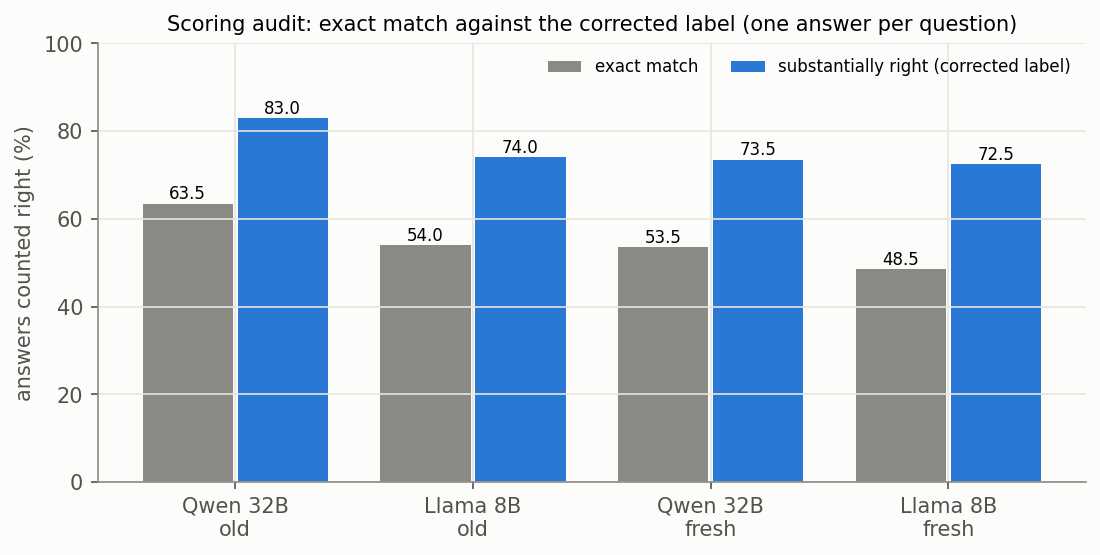

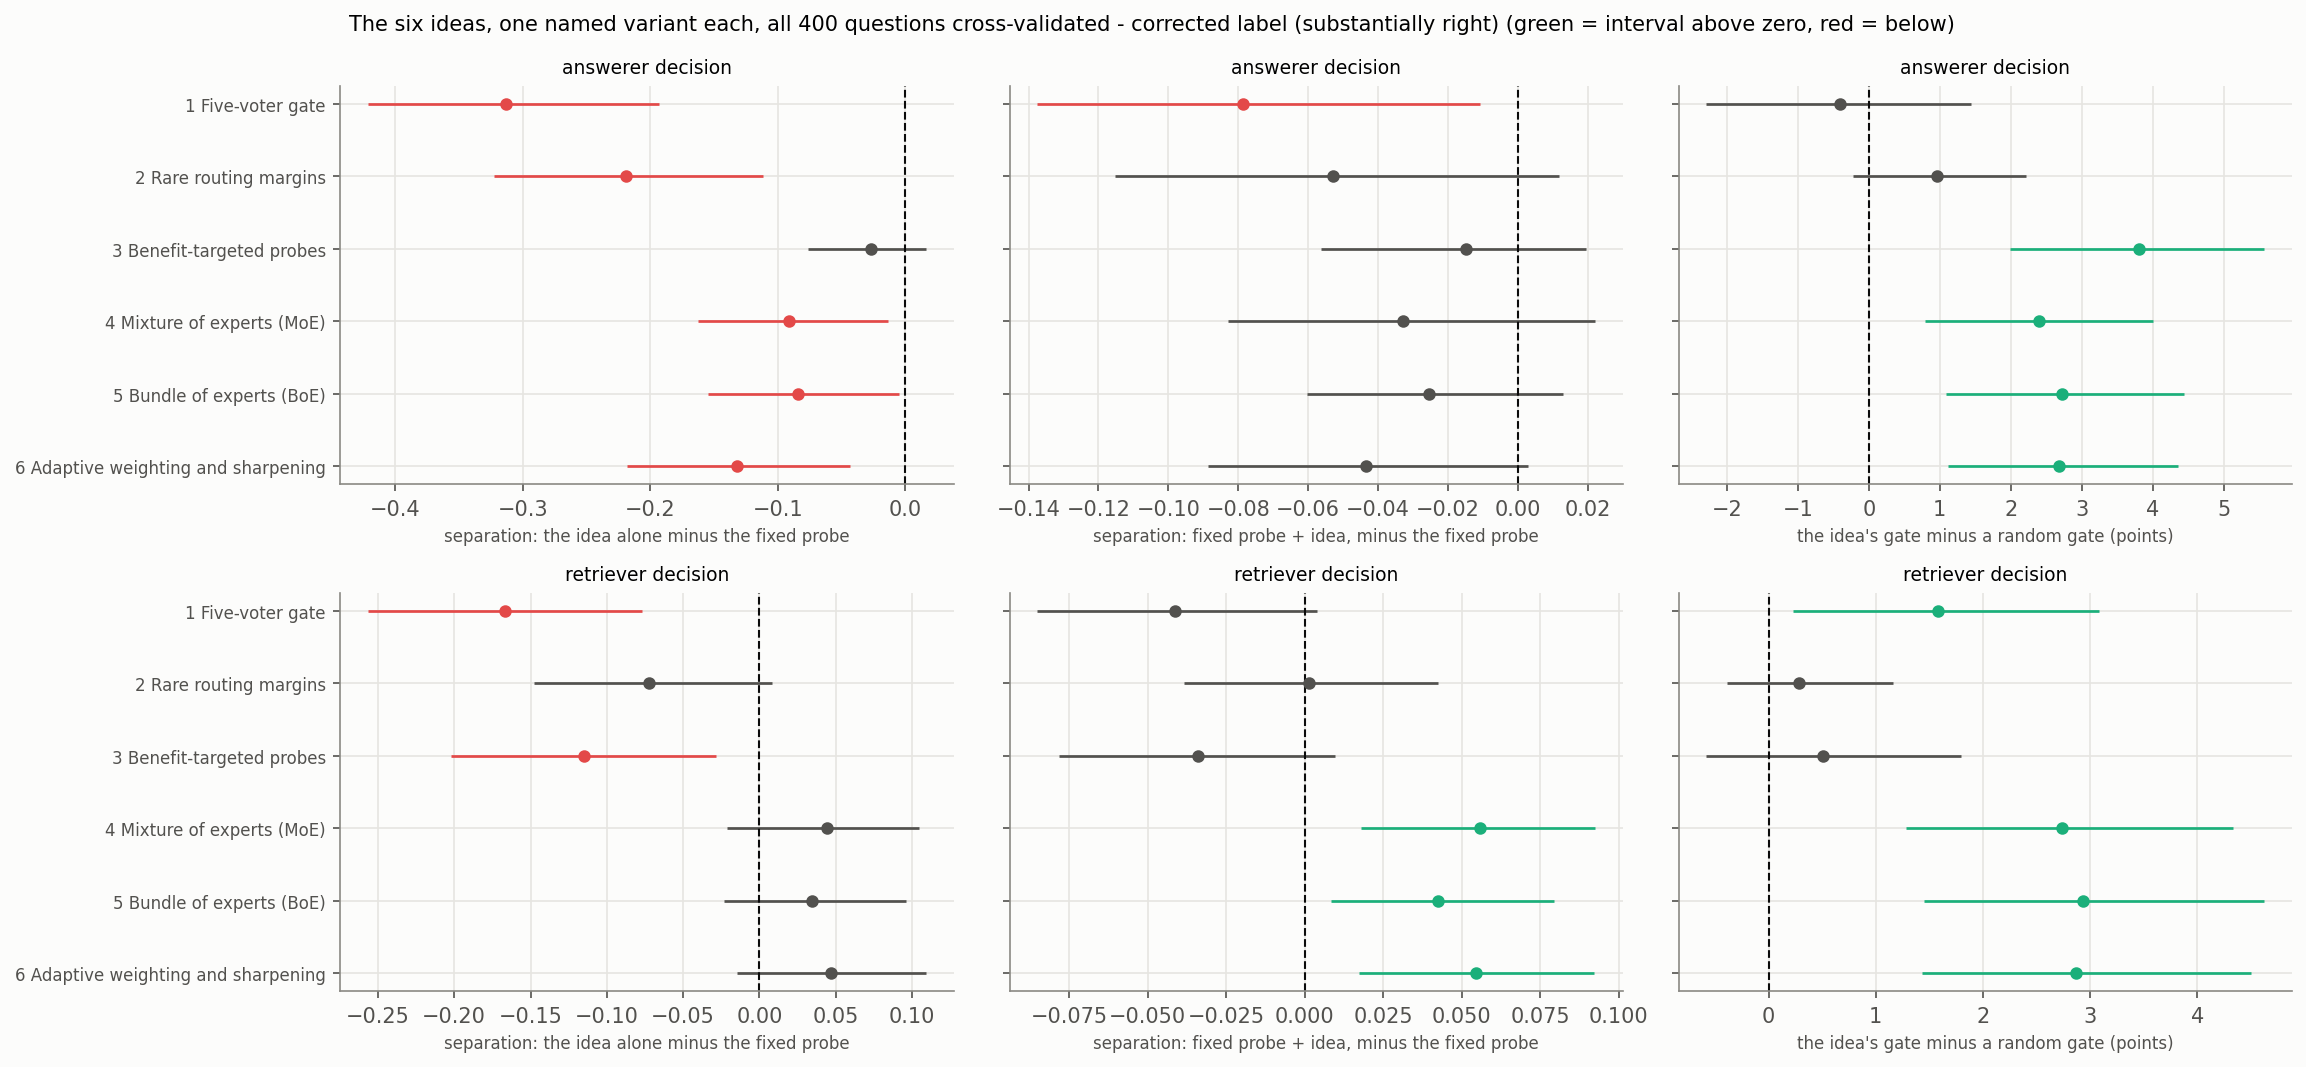

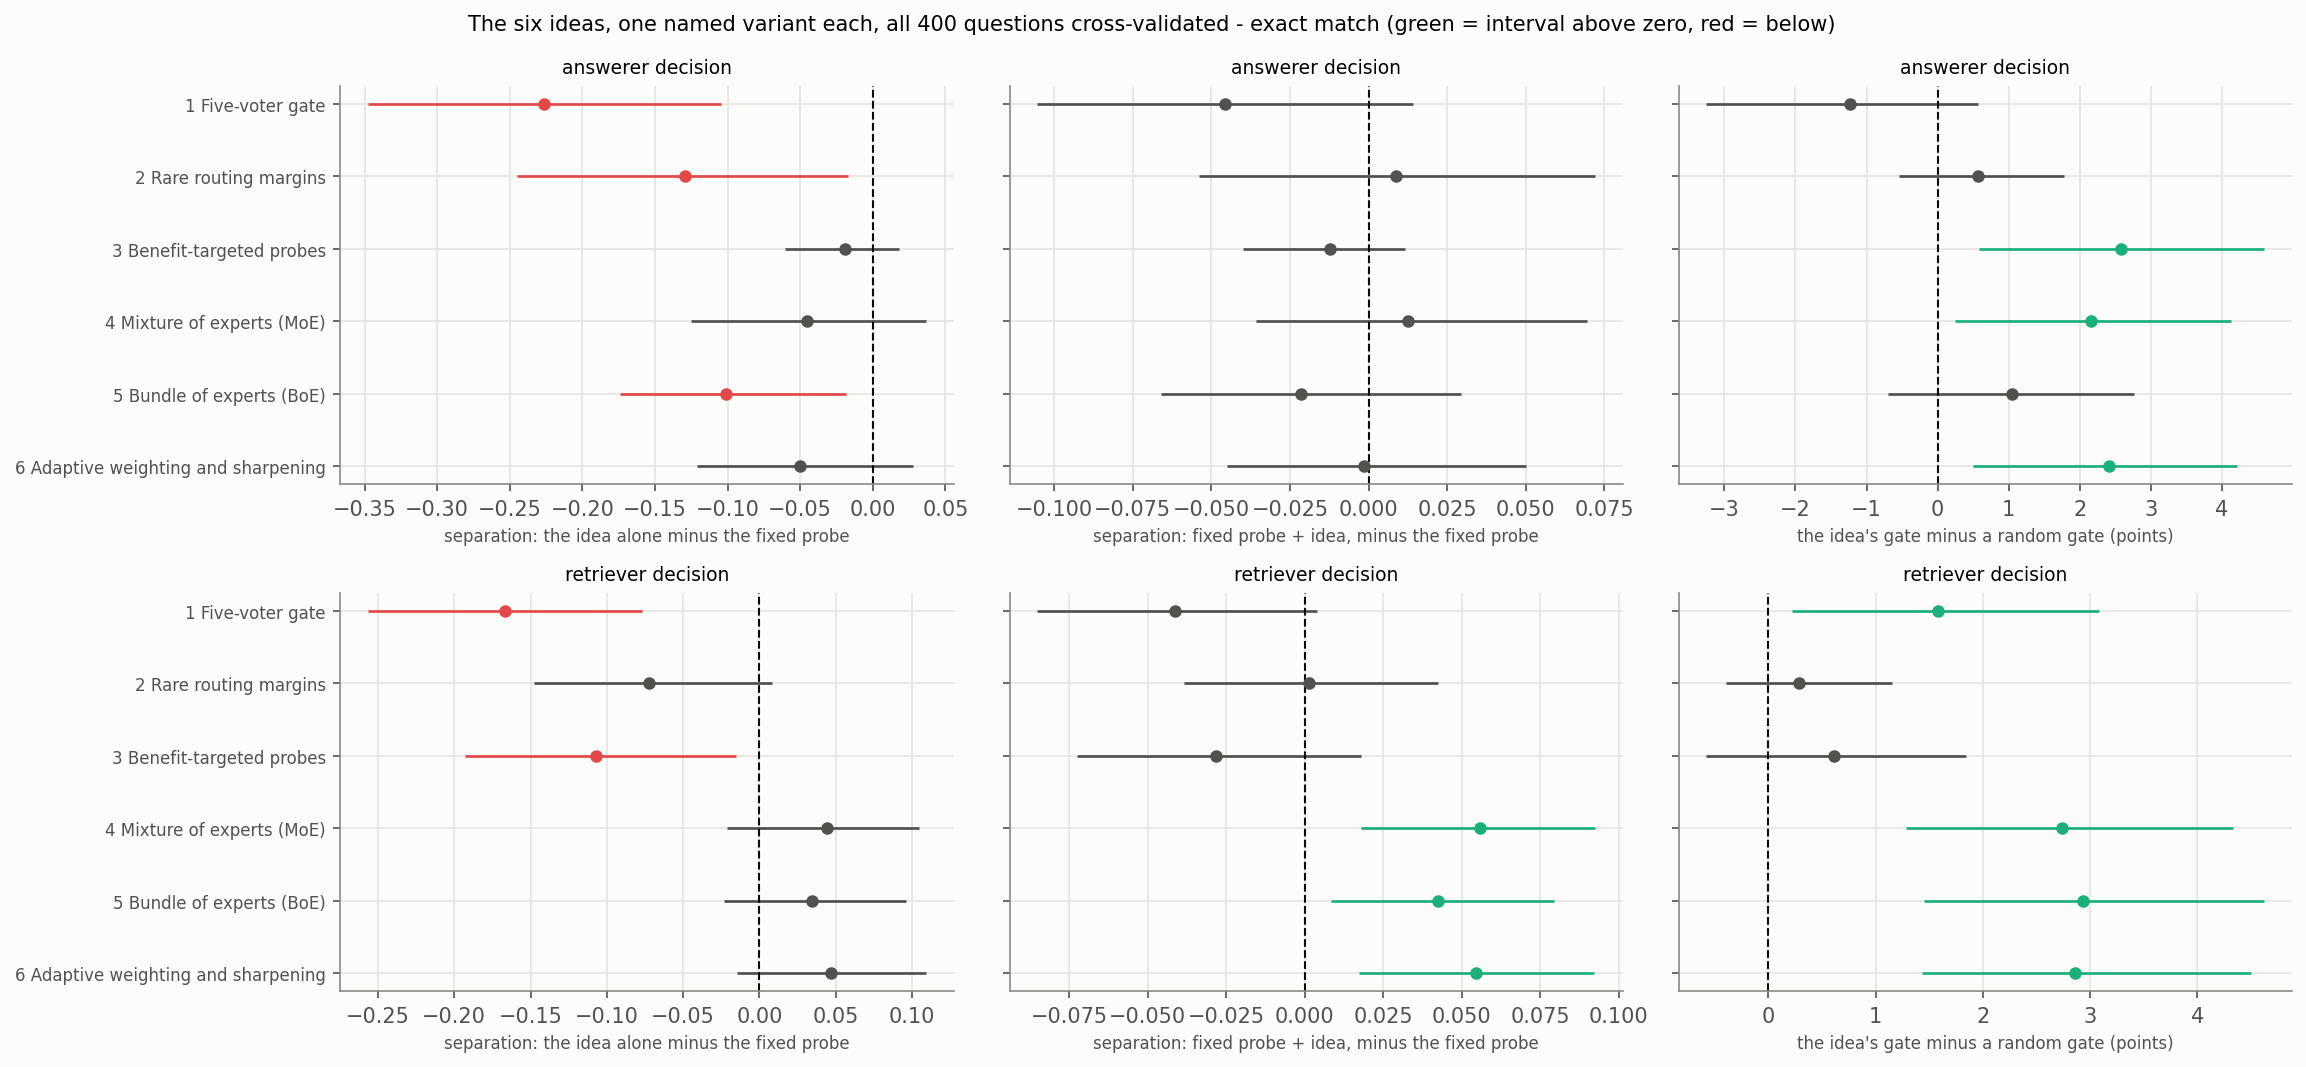

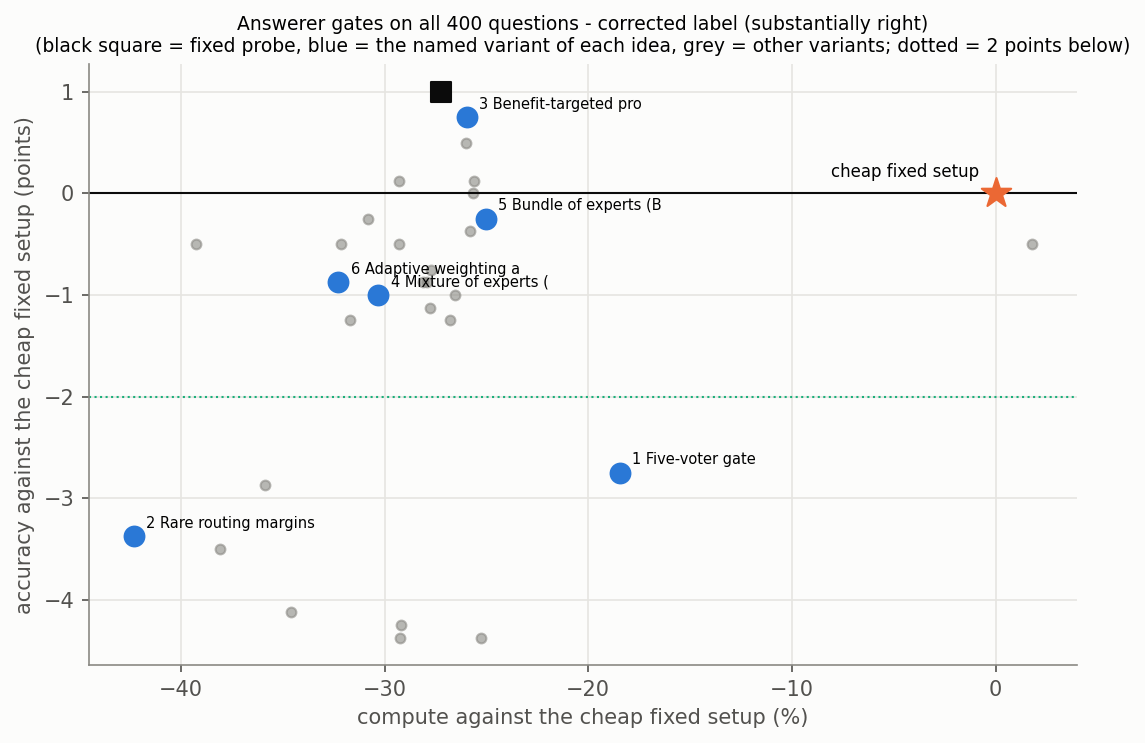

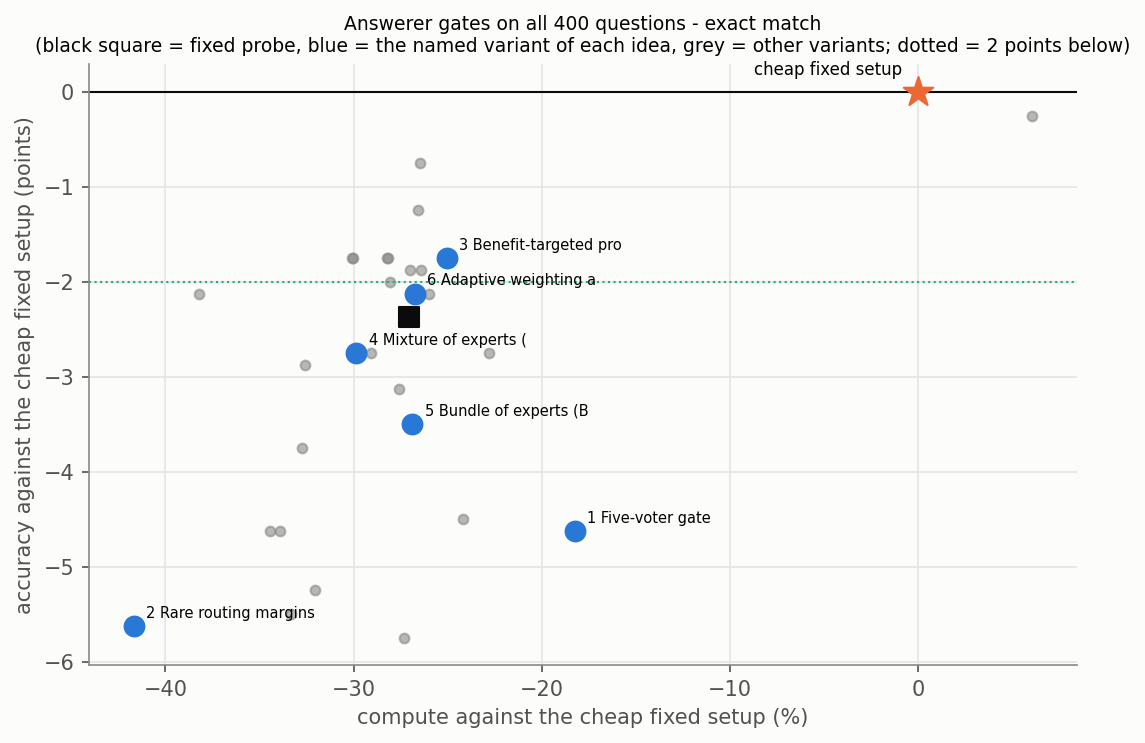

Excel workbook: /content/drive/MyDrive/0_EngD_assignments/0_Small_Big_Model_Switching/runs/Set_2__question-reading-routers/20261008-090219_cpu_ideas/results/set5g_ideas.xlsx

ALL DONE in 36 min.
Saved to Drive.


In [5]:
cmd = [sys.executable, "-u", f"{CODE_DIR}/experts.py", "run", "--old_sweep", OLD_SWEEP, "--old_hidden", OLD_HIDDEN, "--old_data", OLD_DATA,
       "--fresh_run", FRESH_RUN, "--fresh_data", FRESH_DATA, "--run_dir", RUN_DIR, "--cv_repeats", str(CV_REPEATS)] + ([] if USE_EMBEDDING else ["--no_embedding"])
with open(f"{RUN_DIR}/logs/experts.log", "a") as log:
    p = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1)
    for line in p.stdout:
        log.write(line)
        if "Warning" not in line and "warn" not in line:
            print(line, end="")
    p.wait()
assert p.returncode == 0, f"failed - see {RUN_DIR}/logs/experts.log"
from IPython.display import Image, Markdown, display
display(Markdown(open(f"{RUN_DIR}/results/summary.md").read()))
for f in sorted(glob.glob(f"{RUN_DIR}/results/charts/*.png")):
    display(Image(f))
json.dump({"session": SESSION, "seconds": round(time.time() - T_START)}, open(f"{RUN_DIR}/session.json", "w"), indent=1)
print("Excel workbook:", f"{RUN_DIR}/results/set5g_ideas.xlsx")
print(f"\nALL DONE in {(time.time() - T_START) / 60:.0f} min.")
try:
    drive.flush_and_unmount()
    print("Saved to Drive.")
except Exception as e:
    print("Drive flush skipped:", e)